# MIMIC-IV Cohort Analysis: LR vs NS and AKI

**Study:** Initial Lactated Ringer's vs Normal Saline and Subsequent AKI in ICU Patients  
**Dataset:** MIMIC-IV v3.1  
**Author:** Ahmed Soliman  
**Purpose:** Feasibility audit — population description, exposure identification, baseline kidney function, and cohort overlap diagnostics

---

## Outline
1. Setup & data loading
2. Overall MIMIC-IV population
3. ICU cohort construction (first ICU stay, age ≥18)
4. Fluid exposure identification (LR vs NS itemids)
5. Cohort flow diagram
6. Baseline demographics and clinical characteristics by treatment group
7. Baseline kidney function (creatinine availability and timing)
8. Outcome availability (follow-up creatinine, death, discharge)
9. Propensity score overlap diagnostics
10. Summary findings and feasibility notes

## 1. Setup & Data Loading

In [38]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:.3f}')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
sns.set_style('whitegrid')

MIMIC = '/home/ahmed.soliman/blue_prismap-ai-core/Ahmed/DigitalTwins/MDT/mimiciv/3.1'
HOSP  = os.path.join(MIMIC, 'hosp')
ICU   = os.path.join(MIMIC, 'icu')

print(f'MIMIC-IV path: {MIMIC}')
print('Checking files...')
for f in ['hosp/patients.csv', 'hosp/admissions.csv', 'icu/icustays.csv',
          'icu/inputevents.csv', 'icu/d_items.csv',
          'hosp/labevents.csv', 'hosp/d_labitems.csv',
          'hosp/diagnoses_icd.csv']:
    full = os.path.join(MIMIC, f)
    exists = os.path.exists(full)
    size = os.path.getsize(full)/1e6 if exists else 0
    print(f'  {f:45s}  {"OK":3s}  {size:8.1f} MB')

MIMIC-IV path: /home/ahmed.soliman/blue_prismap-ai-core/Ahmed/DigitalTwins/MDT/mimiciv/3.1
Checking files...
  hosp/patients.csv                              OK       12.1 MB
  hosp/admissions.csv                            OK       94.2 MB
  icu/icustays.csv                               OK       14.7 MB
  icu/inputevents.csv                            OK     2868.9 MB
  icu/d_items.csv                                OK        0.4 MB
  hosp/labevents.csv                             OK    18402.9 MB
  hosp/d_labitems.csv                            OK        0.1 MB
  hosp/diagnoses_icd.csv                         OK      181.4 MB


In [39]:
# Load reference tables (small)
d_items    = pd.read_csv(os.path.join(ICU, 'd_items.csv'))
d_labitems = pd.read_csv(os.path.join(HOSP, 'd_labitems.csv'))

# Load core cohort tables
patients   = pd.read_csv(os.path.join(HOSP, 'patients.csv'))
admissions = pd.read_csv(os.path.join(HOSP, 'admissions.csv'),
                         parse_dates=['admittime','dischtime','deathtime',
                                      'edregtime','edouttime'])
icustays   = pd.read_csv(os.path.join(ICU, 'icustays.csv'),
                         parse_dates=['intime','outtime'])

print(f'patients:   {len(patients):,} rows')
print(f'admissions: {len(admissions):,} rows')
print(f'icustays:   {len(icustays):,} rows')

patients:   364,627 rows
admissions: 546,028 rows
icustays:   94,458 rows


## 2. Overall MIMIC-IV Population

In [40]:
print('=== MIMIC-IV v3.1 Overall Population ===')
print(f'Unique patients:        {patients.subject_id.nunique():>10,}')
print(f'Total admissions:       {admissions.hadm_id.nunique():>10,}')
print(f'Total ICU stays:        {icustays.stay_id.nunique():>10,}')
print(f'Patients with ICU stay: {icustays.subject_id.nunique():>10,}')
print()

# Gender distribution
g = patients['gender'].value_counts()
print('Gender (all patients):')
for k, v in g.items():
    print(f'  {k}: {v:,} ({v/len(patients)*100:.1f}%)')
print()

# Age distribution (anchor_age)
print(f'Age (anchor_age):')
print(patients['anchor_age'].describe().to_string())
print()

# Anchor year groups
print('Anchor year group distribution:')
print(patients['anchor_year_group'].value_counts().to_string())

=== MIMIC-IV v3.1 Overall Population ===
Unique patients:           364,627
Total admissions:          546,028
Total ICU stays:            94,458
Patients with ICU stay:     65,366

Gender (all patients):
  F: 191,984 (52.7%)
  M: 172,643 (47.3%)

Age (anchor_age):
count   364627.000
mean        48.875
std         20.943
min         18.000
25%         29.000
50%         48.000
75%         65.000
max         91.000

Anchor year group distribution:
anchor_year_group
2008 - 2010    101607
2011 - 2013     76266
2014 - 2016     71640
2017 - 2019     65941
2020 - 2022     49173


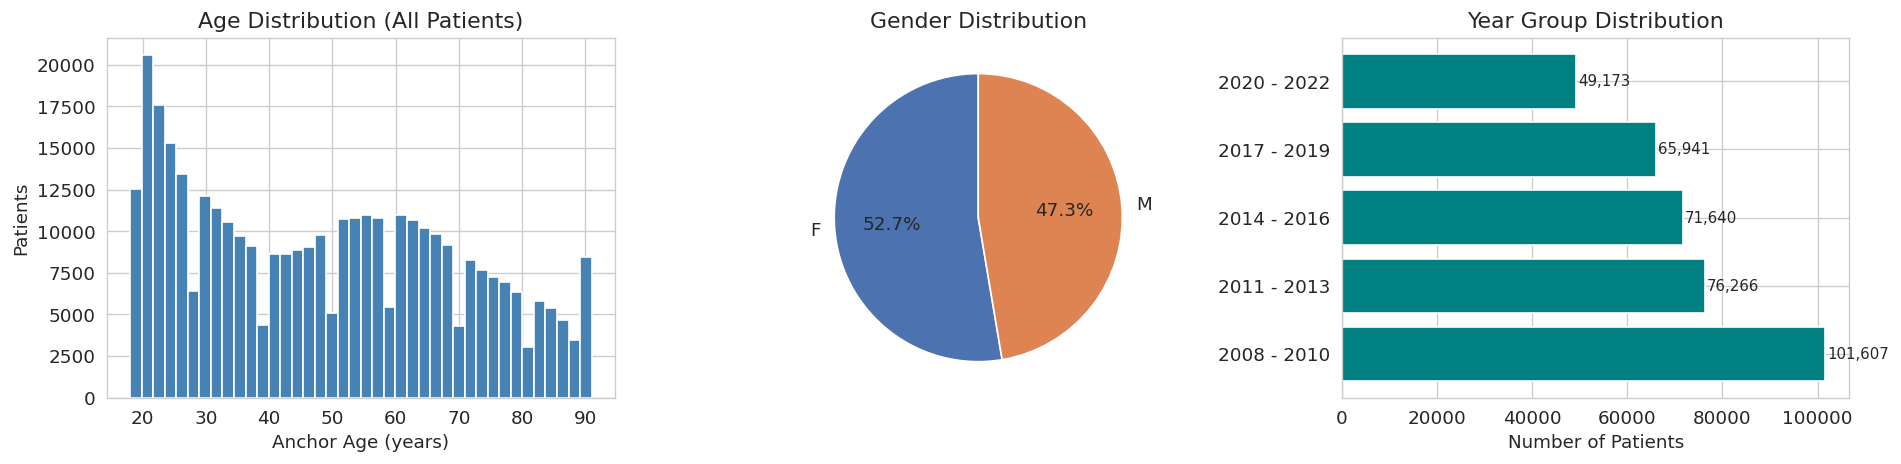

Figure saved: fig_01_overall_population.png


In [41]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Age distribution
axes[0].hist(patients['anchor_age'], bins=40, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Anchor Age (years)')
axes[0].set_ylabel('Patients')
axes[0].set_title('Age Distribution (All Patients)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:.0f}'))

# Gender pie
g_counts = patients['gender'].value_counts()
axes[1].pie(g_counts, labels=g_counts.index, autopct='%1.1f%%',
            colors=['#4C72B0','#DD8452'], startangle=90)
axes[1].set_title('Gender Distribution')

# Anchor year group
yg = patients['anchor_year_group'].value_counts().sort_index()
axes[2].barh(yg.index, yg.values, color='teal')
axes[2].set_xlabel('Number of Patients')
axes[2].set_title('Year Group Distribution')
for i, v in enumerate(yg.values):
    axes[2].text(v + 500, i, f'{v:,}', va='center', fontsize=9)

plt.tight_layout()
plt.savefig('fig_01_overall_population.png', bbox_inches='tight')
plt.show()
print('Figure saved: fig_01_overall_population.png')

## 3. ICU Cohort Construction

In [42]:
# Merge icustays with patient demographics
icu = icustays.merge(patients[['subject_id','gender','anchor_age','dod']], on='subject_id')
# Merge with admissions for insurance, race, etc.
icu = icu.merge(admissions[['subject_id','hadm_id','admittime','dischtime',
                              'deathtime','insurance','language','marital_status',
                              'race','hospital_expire_flag','admission_type']],
                on=['subject_id','hadm_id'])

print(f'All ICU stays: {len(icu):,}')

# Step 1: Adult patients (age >= 18)
icu_adult = icu[icu['anchor_age'] >= 18].copy()
print(f'Adult ICU stays (age>=18): {len(icu_adult):,}')

# Step 2: First ICU stay per patient
icu_first = icu_adult.sort_values('intime').groupby('subject_id').first().reset_index()
print(f'First ICU stay per patient: {len(icu_first):,}')

# Compute ICU LOS
icu_first['los_hours'] = (icu_first['outtime'] - icu_first['intime']).dt.total_seconds() / 3600

# Summary
print(f'\nFirst ICU stay LOS (hours):')
print(icu_first['los_hours'].describe())
print(f'\nICU type distribution (first stay):')
print(icu_first['first_careunit'].value_counts().head(10))

All ICU stays: 94,458
Adult ICU stays (age>=18): 94,458
First ICU stay per patient: 65,366

First ICU stay LOS (hours):
count   65355.000
mean       84.571
std       125.206
min         0.030
25%        26.249
50%        45.889
75%        89.277
max      3832.003
Name: los_hours, dtype: float64

ICU type distribution (first stay):
first_careunit
Medical Intensive Care Unit (MICU)                  12517
Cardiac Vascular Intensive Care Unit (CVICU)        11520
Medical/Surgical Intensive Care Unit (MICU/SICU)    10053
Surgical Intensive Care Unit (SICU)                  9068
Trauma SICU (TSICU)                                  7914
Coronary Care Unit (CCU)                             7371
Neuro Intermediate                                   4314
Neuro Surgical Intensive Care Unit (Neuro SICU)      1313
Neuro Stepdown                                       1102
Surgery/Vascular/Intermediate                          95
Name: count, dtype: int64


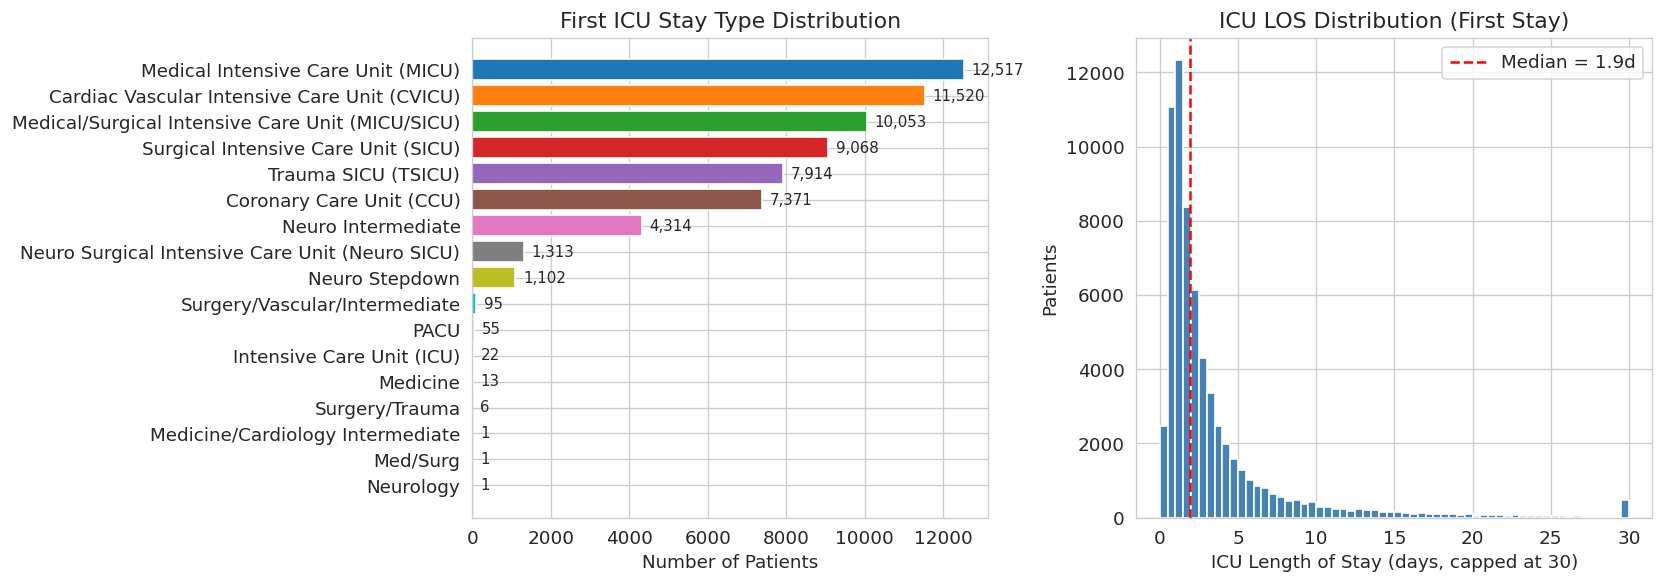

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ICU type distribution
icu_type_counts = icu_first['first_careunit'].value_counts()
colors = sns.color_palette('tab10', len(icu_type_counts))
axes[0].barh(icu_type_counts.index[::-1], icu_type_counts.values[::-1], color=colors[::-1])
axes[0].set_xlabel('Number of Patients')
axes[0].set_title('First ICU Stay Type Distribution')
for i, v in enumerate(icu_type_counts.values[::-1]):
    axes[0].text(v + 200, i, f'{v:,}', va='center', fontsize=9)

# LOS distribution (capped at 30 days for visualization)
los_days = icu_first['los_hours'] / 24
axes[1].hist(los_days.clip(0, 30), bins=60, color='steelblue', edgecolor='white')
axes[1].set_xlabel('ICU Length of Stay (days, capped at 30)')
axes[1].set_ylabel('Patients')
axes[1].set_title('ICU LOS Distribution (First Stay)')
axes[1].axvline(los_days.median(), color='red', linestyle='--',
                label=f'Median = {los_days.median():.1f}d')
axes[1].legend()

plt.tight_layout()
plt.savefig('fig_02_icu_cohort.png', bbox_inches='tight')
plt.show()

## 4. Fluid Exposure Identification (LR vs NS)

In [44]:
# Define LR and NS itemids
# LR: pure LR (225828) — the main active item; also Ringers Lactate (220955, legacy)
# NS: NaCl 0.9% (225158) — main active; also Saline 0.9% (220954, legacy)
LR_ITEMS = {225828: 'LR', 220955: 'Ringers Lactate (legacy)',
            220953: 'Ringers (legacy)', 225827: 'D5LR'}
NS_ITEMS = {225158: 'NaCl 0.9%', 220954: 'Saline 0.9% (legacy)'}

print('Fluid item IDs confirmed in d_items:')
fluid_items = d_items[d_items['itemid'].isin(list(LR_ITEMS.keys()) + list(NS_ITEMS.keys()))]
print(fluid_items[['itemid','label','abbreviation','category']].to_string(index=False))

Fluid item IDs confirmed in d_items:
 itemid           label    abbreviation                    category
 220953         Ringers         Ringers Fluids - Other (Not In Use)
 220954     Saline 0,9%     Saline 0,9% Fluids - Other (Not In Use)
 220955 Ringers Lactate Ringers Lactate Fluids - Other (Not In Use)
 225158       NaCl 0.9%       NaCl 0.9%               Fluids/Intake
 225827            D5LR            D5LR               Fluids/Intake
 225828              LR              LR               Fluids/Intake


In [45]:
# Load inputevents — this is large, read with usecols
print('Loading inputevents (large file — may take a moment)...')
ie = pd.read_csv(
    os.path.join(ICU, 'inputevents.csv'),
    usecols=['subject_id','hadm_id','stay_id','starttime','itemid',
             'amount','amountuom','ordercategoryname','statusdescription'],
    parse_dates=['starttime']
)
print(f'inputevents rows: {len(ie):,}')

# Keep only LR and NS events
all_fluid_ids = list(LR_ITEMS.keys()) + list(NS_ITEMS.keys())
ie_fluids = ie[ie['itemid'].isin(all_fluid_ids)].copy()
ie_fluids['fluid_type'] = ie_fluids['itemid'].map(
    {**{k: 'LR' for k in LR_ITEMS}, **{k: 'NS' for k in NS_ITEMS}}
)
ie_fluids['fluid_label'] = ie_fluids['itemid'].map(
    {**LR_ITEMS, **NS_ITEMS}
)

# Keep only FinishedRunning / completed events (exclude cancelled/rewritten)
print('\nStatus description counts:')
print(ie_fluids['statusdescription'].value_counts())

ie_fluids = ie_fluids[ie_fluids['statusdescription'] == 'FinishedRunning'].copy()
print(f'\nAfter FinishedRunning filter: {len(ie_fluids):,} events')
print(f'Unique stays with fluid: {ie_fluids.stay_id.nunique():,}')

print('\nEvents by item:')
print(ie_fluids.groupby(['fluid_label','fluid_type'])['amount'].agg(['count','sum','mean']).round(0))

Loading inputevents (large file — may take a moment)...
inputevents rows: 10,953,713

Status description counts:
statusdescription
ChangeDose/Rate    737705
FinishedRunning    732158
Stopped            143878
Paused              94953
Bolus                 695
Reported                1
Name: count, dtype: int64

After FinishedRunning filter: 732,158 events
Unique stays with fluid: 67,039

Events by item:
                         count           sum    mean
fluid_label fluid_type                              
D5LR        LR            1945   1675881.000 862.000
LR          LR           95998  72902930.000 759.000
NaCl 0.9%   NS          634215 149999086.000 237.000


In [46]:
# Find FIRST qualifying fluid event per stay (within 24h of ICU admission)
# Merge with ICU stays to get intime
ie_fluids = ie_fluids.merge(icustays[['stay_id','intime']], on='stay_id')
ie_fluids['hours_from_icu_admit'] = (
    (ie_fluids['starttime'] - ie_fluids['intime']).dt.total_seconds() / 3600
)

# Within first 24h of ICU admission
ie_24h = ie_fluids[ie_fluids['hours_from_icu_admit'].between(0, 24)].copy()
print(f'Fluid events within first 24h of ICU admit: {len(ie_24h):,}')
print(f'Unique stays: {ie_24h.stay_id.nunique():,}')

# First fluid event per stay
first_fluid = (
    ie_24h.sort_values('starttime')
    .groupby('stay_id')
    .first()
    .reset_index()
    [['stay_id','starttime','itemid','fluid_type','fluid_label','amount','hours_from_icu_admit','intime']]
)
first_fluid.columns = ['stay_id','fluid_starttime','fluid_itemid','fluid_type',
                        'fluid_label','fluid_amount_mL','hours_from_icu_admit','icu_intime']

print(f'\nStays with first qualifying fluid in 24h: {len(first_fluid):,}')
print('\nFirst fluid type distribution:')
fc = first_fluid['fluid_type'].value_counts()
for k, v in fc.items():
    print(f'  {k}: {v:,} ({v/len(first_fluid)*100:.1f}%)')

print('\nFirst fluid label breakdown:')
print(first_fluid['fluid_label'].value_counts())

Fluid events within first 24h of ICU admit: 234,896
Unique stays: 62,902

Stays with first qualifying fluid in 24h: 62,902

First fluid type distribution:
  NS: 44,106 (70.1%)
  LR: 18,796 (29.9%)

First fluid label breakdown:
fluid_label
NaCl 0.9%    44106
LR           18579
D5LR           217
Name: count, dtype: int64


In [47]:
# Merge first fluid with first ICU stay cohort
cohort = icu_first.merge(first_fluid, on='stay_id', how='inner')
print(f'Cohort (first ICU stay, adult, with first LR/NS within 24h): {len(cohort):,}')
print(f'\nGroup sizes:')
print(cohort['fluid_type'].value_counts())

# Time zero = fluid_starttime
# Follow-up window: 7 days from time zero
cohort['followup_end'] = cohort['fluid_starttime'] + pd.Timedelta(days=7)

Cohort (first ICU stay, adult, with first LR/NS within 24h): 44,767

Group sizes:
fluid_type
NS    29851
LR    14916
Name: count, dtype: int64


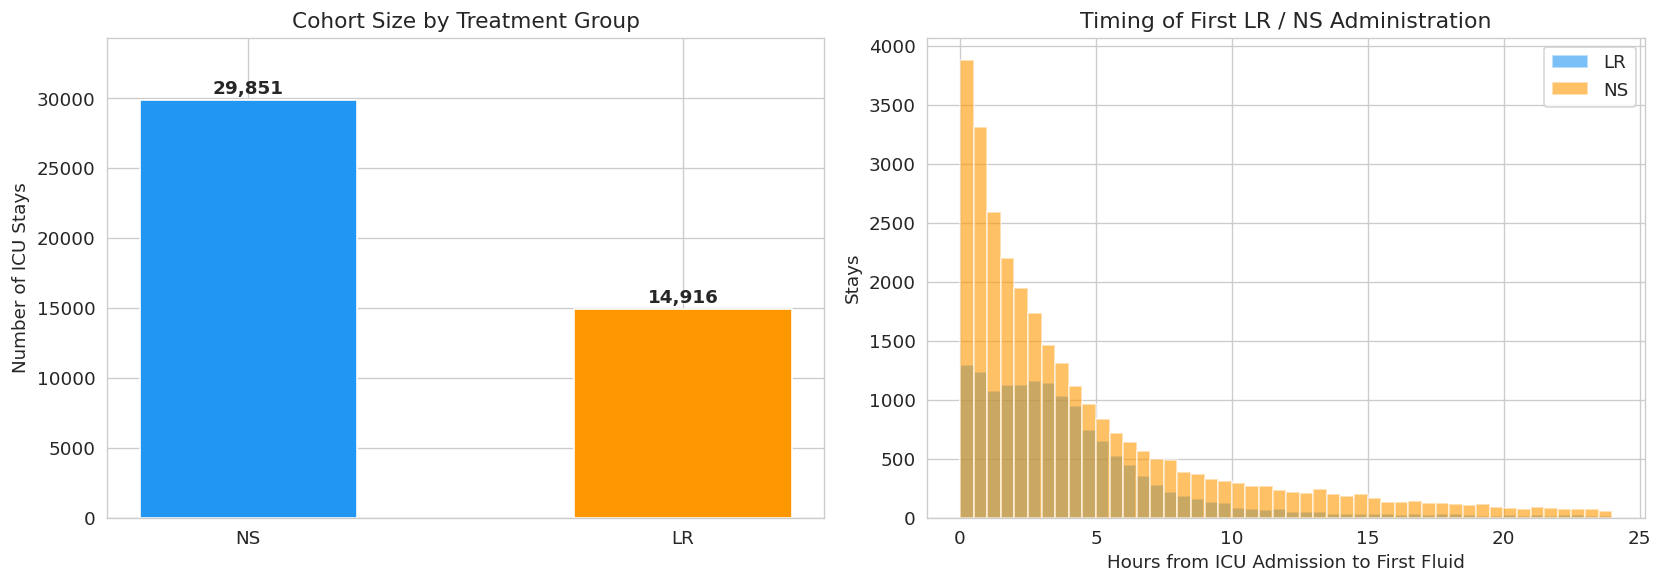

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Group sizes
fc = cohort['fluid_type'].value_counts()
bars = axes[0].bar(fc.index, fc.values, color=['#2196F3','#FF9800'], width=0.5)
for bar, val in zip(bars, fc.values):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'{val:,}', ha='center', va='bottom', fontweight='bold')
axes[0].set_title('Cohort Size by Treatment Group', fontsize=13)
axes[0].set_ylabel('Number of ICU Stays')
axes[0].set_ylim(0, max(fc.values) * 1.15)

# Time to first fluid from ICU admission
for fluid, color in [('LR','#2196F3'), ('NS','#FF9800')]:
    sub = cohort[cohort['fluid_type'] == fluid]['hours_from_icu_admit']
    axes[1].hist(sub, bins=48, alpha=0.6, label=fluid, color=color, edgecolor='white')
axes[1].set_xlabel('Hours from ICU Admission to First Fluid')
axes[1].set_ylabel('Stays')
axes[1].set_title('Timing of First LR / NS Administration')
axes[1].legend()

plt.tight_layout()
plt.savefig('fig_03_exposure.png', bbox_inches='tight')
plt.show()

## 5. Cohort Flow Diagram

In [49]:
# Compute flow numbers
n_patients        = patients.subject_id.nunique()
n_icu_all         = len(icu)
n_icu_adult       = len(icu_adult)
n_icu_first       = len(icu_first)
n_with_fluid_24h  = len(cohort)
n_lr              = (cohort['fluid_type'] == 'LR').sum()
n_ns              = (cohort['fluid_type'] == 'NS').sum()

print('=== COHORT FLOW ===')
print(f'Total MIMIC-IV patients:                    {n_patients:>10,}')
print(f'Patients with any ICU stay:                 {icu.subject_id.nunique():>10,}')
print(f'All ICU stays:                              {n_icu_all:>10,}')
print(f'  Excluded (age <18):                       {n_icu_all - n_icu_adult:>10,}')
print(f'Adult ICU stays:                            {n_icu_adult:>10,}')
print(f'  Excluded (not first stay):                {n_icu_adult - n_icu_first:>10,}')
print(f'First adult ICU stays:                      {n_icu_first:>10,}')
print(f'  Excluded (no LR/NS within 24h):           {n_icu_first - n_with_fluid_24h:>10,}')
print(f'Analytic cohort (LR or NS within 24h):      {n_with_fluid_24h:>10,}')
print(f'  Lactated Ringer\'s (LR):                  {n_lr:>10,} ({n_lr/n_with_fluid_24h*100:.1f}%)')
print(f'  Normal Saline (NS):                       {n_ns:>10,} ({n_ns/n_with_fluid_24h*100:.1f}%)')

=== COHORT FLOW ===
Total MIMIC-IV patients:                       364,627
Patients with any ICU stay:                     65,366
All ICU stays:                                  94,458
  Excluded (age <18):                                0
Adult ICU stays:                                94,458
  Excluded (not first stay):                    29,092
First adult ICU stays:                          65,366
  Excluded (no LR/NS within 24h):               20,599
Analytic cohort (LR or NS within 24h):          44,767
  Lactated Ringer's (LR):                      14,916 (33.3%)
  Normal Saline (NS):                           29,851 (66.7%)


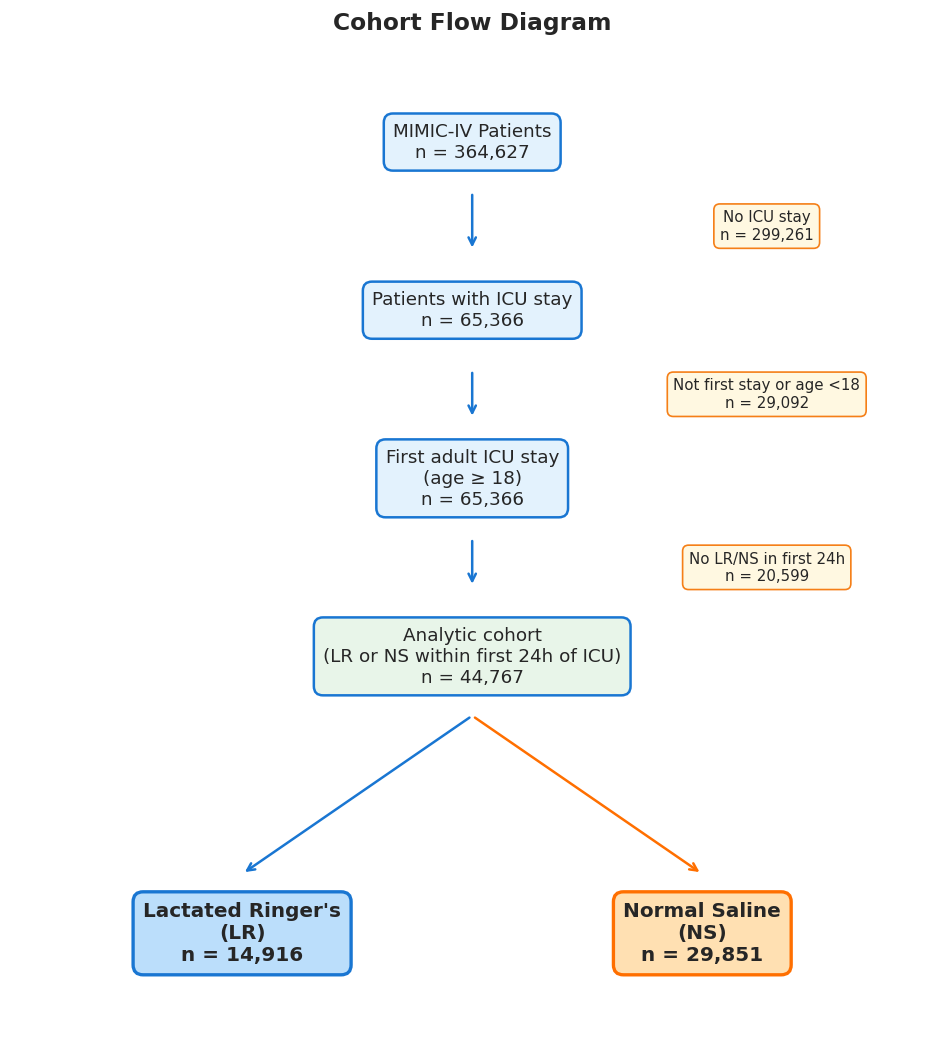

In [50]:
fig, ax = plt.subplots(figsize=(8, 9))
ax.axis('off')

boxes = [
    (0.5, 0.92, f'MIMIC-IV Patients\nn = {n_patients:,}', '#E3F2FD'),
    (0.5, 0.75, f'Patients with ICU stay\nn = {icu.subject_id.nunique():,}', '#E3F2FD'),
    (0.5, 0.58, f'First adult ICU stay\n(age ≥ 18)\nn = {n_icu_first:,}', '#E3F2FD'),
    (0.5, 0.40, f'Analytic cohort\n(LR or NS within first 24h of ICU)\nn = {n_with_fluid_24h:,}', '#E8F5E9'),
]
exclusions = [
    (0.82, 0.835, f'No ICU stay\nn = {n_patients - icu.subject_id.nunique():,}'),
    (0.82, 0.665, f'Not first stay or age <18\nn = {n_icu_adult - n_icu_first + n_icu_all - n_icu_adult:,}'),
    (0.82, 0.490, f'No LR/NS in first 24h\nn = {n_icu_first - n_with_fluid_24h:,}'),
]

for x, y, text, color in boxes:
    ax.text(x, y, text, ha='center', va='center', fontsize=11,
            bbox=dict(boxstyle='round,pad=0.5', facecolor=color, edgecolor='#1976D2', lw=1.5),
            transform=ax.transAxes)

for x, y, text in exclusions:
    ax.text(x, y, text, ha='center', va='center', fontsize=9,
            bbox=dict(boxstyle='round,pad=0.4', facecolor='#FFF8E1', edgecolor='#F57F17', lw=1),
            transform=ax.transAxes)

# Arrows (down)
for y_from, y_to in [(0.87, 0.81), (0.69, 0.64), (0.52, 0.47)]:
    ax.annotate('', xy=(0.5, y_to), xytext=(0.5, y_from),
                arrowprops=dict(arrowstyle='->', color='#1976D2', lw=1.5),
                xycoords='axes fraction', textcoords='axes fraction')

# Final split
ax.annotate('', xy=(0.25, 0.18), xytext=(0.5, 0.34),
            arrowprops=dict(arrowstyle='->', color='#1976D2', lw=1.5),
            xycoords='axes fraction', textcoords='axes fraction')
ax.annotate('', xy=(0.75, 0.18), xytext=(0.5, 0.34),
            arrowprops=dict(arrowstyle='->', color='#FF6F00', lw=1.5),
            xycoords='axes fraction', textcoords='axes fraction')

ax.text(0.25, 0.12, f'Lactated Ringer\'s\n(LR)\nn = {n_lr:,}', ha='center', va='center',
        fontsize=12, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#BBDEFB', edgecolor='#1976D2', lw=2),
        transform=ax.transAxes)
ax.text(0.75, 0.12, f'Normal Saline\n(NS)\nn = {n_ns:,}', ha='center', va='center',
        fontsize=12, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#FFE0B2', edgecolor='#FF6F00', lw=2),
        transform=ax.transAxes)

ax.set_title('Cohort Flow Diagram', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('fig_04_cohort_flow.png', bbox_inches='tight')
plt.show()

## 6. Baseline Demographics and Clinical Characteristics

In [51]:
def summarize_var(df, col, group_col='fluid_type', groups=('LR','NS'), continuous=True):
    """Return a summary dict for one variable."""
    if continuous:
        rows = []
        for g in groups:
            sub = df.loc[df[group_col] == g, col].dropna()
            rows.append({'Group': g, 'N': len(sub),
                         'Median': sub.median(), 'IQR_lo': sub.quantile(0.25),
                         'IQR_hi': sub.quantile(0.75), 'Mean': sub.mean(), 'SD': sub.std()})
        stat, pval = stats.mannwhitneyu(
            df.loc[df[group_col]=='LR', col].dropna(),
            df.loc[df[group_col]=='NS', col].dropna(), alternative='two-sided'
        )
        return pd.DataFrame(rows), pval
    else:
        ct = pd.crosstab(df[group_col], df[col])
        chi2, pval, _, _ = stats.chi2_contingency(ct)
        return ct, pval

print('=== TABLE 1: Baseline Characteristics by Treatment Group ===')
lr_hdr = f'LR (N={n_lr})'
ns_hdr = f'NS (N={n_ns})'
print(f'{"Variable":35s} {lr_hdr:<25} {ns_hdr:<25} p-value')
print('-' * 95)

# Age
res, pval = summarize_var(cohort, 'anchor_age')
lr_row = res[res['Group']=='LR'].iloc[0]
ns_row = res[res['Group']=='NS'].iloc[0]
print(f'{"Age (years), median [IQR]":35s} '
      f'{lr_row["Median"]:.0f} [{lr_row["IQR_lo"]:.0f}–{lr_row["IQR_hi"]:.0f}]     '
      f'{ns_row["Median"]:.0f} [{ns_row["IQR_lo"]:.0f}–{ns_row["IQR_hi"]:.0f}]     '
      f'{pval:.4f}')

# LOS
res, pval = summarize_var(cohort, 'los_hours')
lr_row = res[res['Group']=='LR'].iloc[0]
ns_row = res[res['Group']=='NS'].iloc[0]
print(f'{"ICU LOS (hours), median [IQR]":35s} '
      f'{lr_row["Median"]:.1f} [{lr_row["IQR_lo"]:.1f}–{lr_row["IQR_hi"]:.1f}]  '
      f'{ns_row["Median"]:.1f} [{ns_row["IQR_lo"]:.1f}–{ns_row["IQR_hi"]:.1f}]  '
      f'{pval:.4f}')

# Fluid amount
res, pval = summarize_var(cohort, 'fluid_amount_mL')
lr_row = res[res['Group']=='LR'].iloc[0]
ns_row = res[res['Group']=='NS'].iloc[0]
print(f'{"First fluid volume (mL), median [IQR]":35s} '
      f'{lr_row["Median"]:.0f} [{lr_row["IQR_lo"]:.0f}–{lr_row["IQR_hi"]:.0f}]  '
      f'{ns_row["Median"]:.0f} [{ns_row["IQR_lo"]:.0f}–{ns_row["IQR_hi"]:.0f}]  '
      f'{pval:.4f}')

print()

# Gender
for g in ['F','M']:
    lr_n = (cohort[cohort['fluid_type']=='LR']['gender'] == g).sum()
    ns_n = (cohort[cohort['fluid_type']=='NS']['gender'] == g).sum()
    label = {'F':'Female','M':'Male'}[g]
    lr_str = f'{lr_n} ({lr_n/n_lr*100:.1f}%)'
    ns_str = f'{ns_n} ({ns_n/n_ns*100:.1f}%)'
    print(f'{label+", n (%)":35s} {lr_str:<25} {ns_str:<25}')

# Hospital mortality
lr_mort = cohort[cohort['fluid_type']=='LR']['hospital_expire_flag'].mean()
ns_mort = cohort[cohort['fluid_type']=='NS']['hospital_expire_flag'].mean()
lr_mort_n = int(cohort[cohort['fluid_type']=='LR']['hospital_expire_flag'].sum())
ns_mort_n = int(cohort[cohort['fluid_type']=='NS']['hospital_expire_flag'].sum())
lr_str = f'{lr_mort_n} ({lr_mort*100:.1f}%)'
ns_str = f'{ns_mort_n} ({ns_mort*100:.1f}%)'
print(f'{"Hospital mortality, n (%)":35s} {lr_str:<25} {ns_str:<25}')

# Admission type
print('\nAdmission type:')
print(pd.crosstab(cohort['fluid_type'], cohort['admission_type']))

=== TABLE 1: Baseline Characteristics by Treatment Group ===
Variable                            LR (N=14916)              NS (N=29851)              p-value
-----------------------------------------------------------------------------------------------
Age (years), median [IQR]           65 [55–75]     65 [52–77]     0.2503
ICU LOS (hours), median [IQR]       46.0 [28.7–79.8]  52.8 [29.9–108.9]  0.0000
First fluid volume (mL), median [IQR] 997 [500–1000]  500 [100–1000]  0.0000

Female, n (%)                       5622 (37.7%)              13617 (45.6%)            
Male, n (%)                         9294 (62.3%)              16234 (54.4%)            
Hospital mortality, n (%)           858 (5.8%)                4311 (14.4%)             

Admission type:
admission_type  AMBULATORY OBSERVATION  DIRECT EMER.  DIRECT OBSERVATION  \
fluid_type                                                                 
LR                                   1           493                   9   
NS     

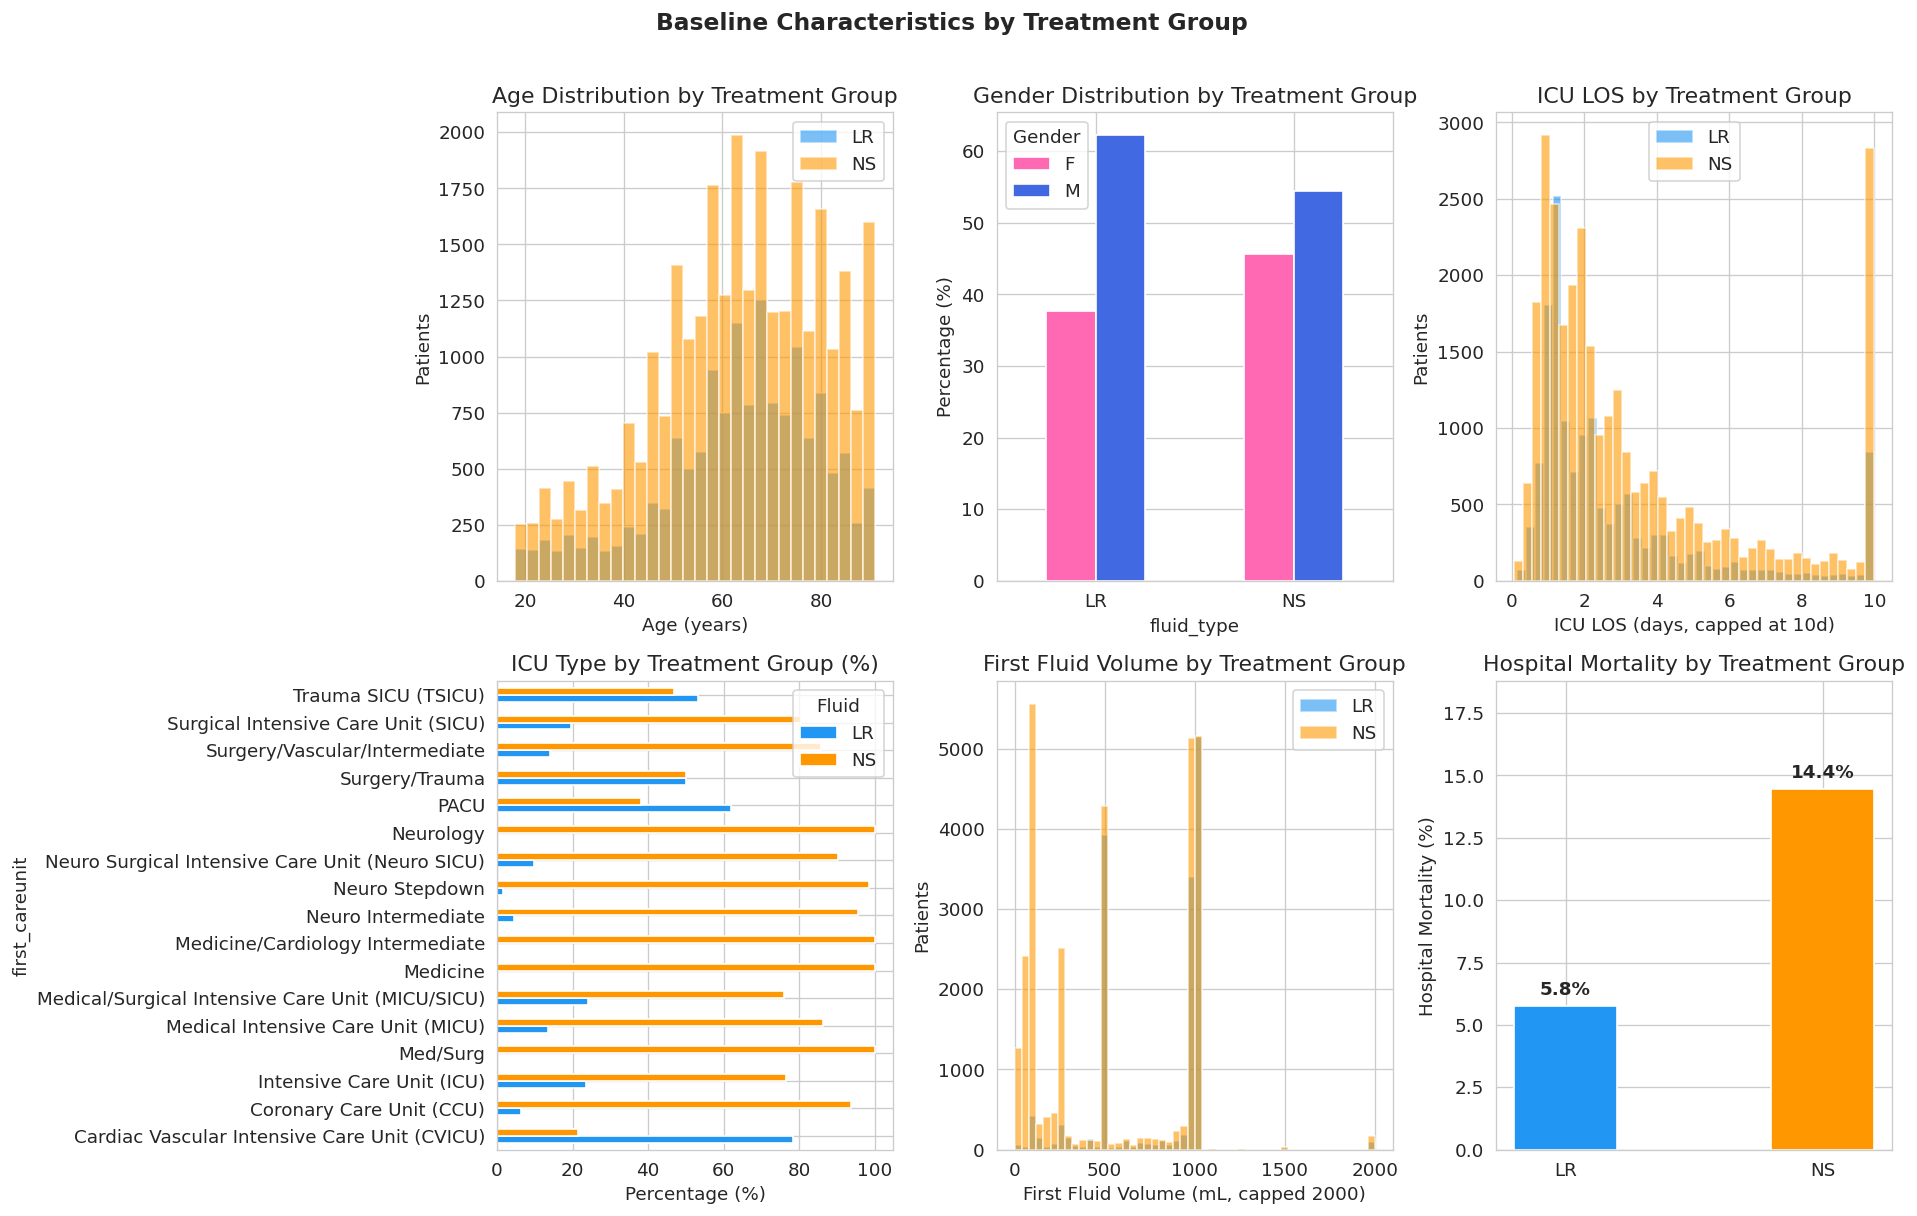

In [52]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

palette = {'LR': '#2196F3', 'NS': '#FF9800'}

# 1. Age by group
for fluid in ['LR','NS']:
    sub = cohort[cohort['fluid_type']==fluid]['anchor_age']
    axes[0].hist(sub, bins=30, alpha=0.6, label=fluid, color=palette[fluid], edgecolor='white')
axes[0].set_xlabel('Age (years)')
axes[0].set_ylabel('Patients')
axes[0].set_title('Age Distribution by Treatment Group')
axes[0].legend()

# 2. Gender
gender_df = cohort.groupby(['fluid_type','gender']).size().unstack(fill_value=0)
gender_pct = gender_df.div(gender_df.sum(axis=1), axis=0) * 100
gender_pct.plot(kind='bar', ax=axes[1], color=['#FF69B4','#4169E1'])
axes[1].set_title('Gender Distribution by Treatment Group')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xticklabels(gender_pct.index, rotation=0)
axes[1].legend(title='Gender')

# 3. ICU LOS
for fluid in ['LR','NS']:
    sub = cohort[cohort['fluid_type']==fluid]['los_hours'].clip(0, 240) / 24
    axes[2].hist(sub, bins=40, alpha=0.6, label=fluid, color=palette[fluid], edgecolor='white')
axes[2].set_xlabel('ICU LOS (days, capped at 10d)')
axes[2].set_ylabel('Patients')
axes[2].set_title('ICU LOS by Treatment Group')
axes[2].legend()

# 4. ICU care unit
icu_counts = cohort.groupby(['first_careunit','fluid_type']).size().unstack(fill_value=0)
icu_pct = icu_counts.div(icu_counts.sum(axis=1), axis=0) * 100
icu_pct.plot(kind='barh', ax=axes[3], color=[palette['LR'], palette['NS']])
axes[3].set_title('ICU Type by Treatment Group (%)')
axes[3].set_xlabel('Percentage (%)')
axes[3].legend(title='Fluid')

# 5. First fluid volume
for fluid in ['LR','NS']:
    sub = cohort[cohort['fluid_type']==fluid]['fluid_amount_mL'].clip(0, 2000)
    axes[4].hist(sub, bins=50, alpha=0.6, label=fluid, color=palette[fluid], edgecolor='white')
axes[4].set_xlabel('First Fluid Volume (mL, capped 2000)')
axes[4].set_ylabel('Patients')
axes[4].set_title('First Fluid Volume by Treatment Group')
axes[4].legend()

# 6. Hospital mortality
mort = cohort.groupby('fluid_type')['hospital_expire_flag'].mean() * 100
bars = axes[5].bar(mort.index, mort.values, color=[palette['LR'], palette['NS']], width=0.4)
for bar, val in zip(bars, mort.values):
    axes[5].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
axes[5].set_ylabel('Hospital Mortality (%)')
axes[5].set_title('Hospital Mortality by Treatment Group')
axes[5].set_ylim(0, max(mort.values) * 1.3)

plt.suptitle('Baseline Characteristics by Treatment Group', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig_05_baseline_characteristics.png', bbox_inches='tight')
plt.show()

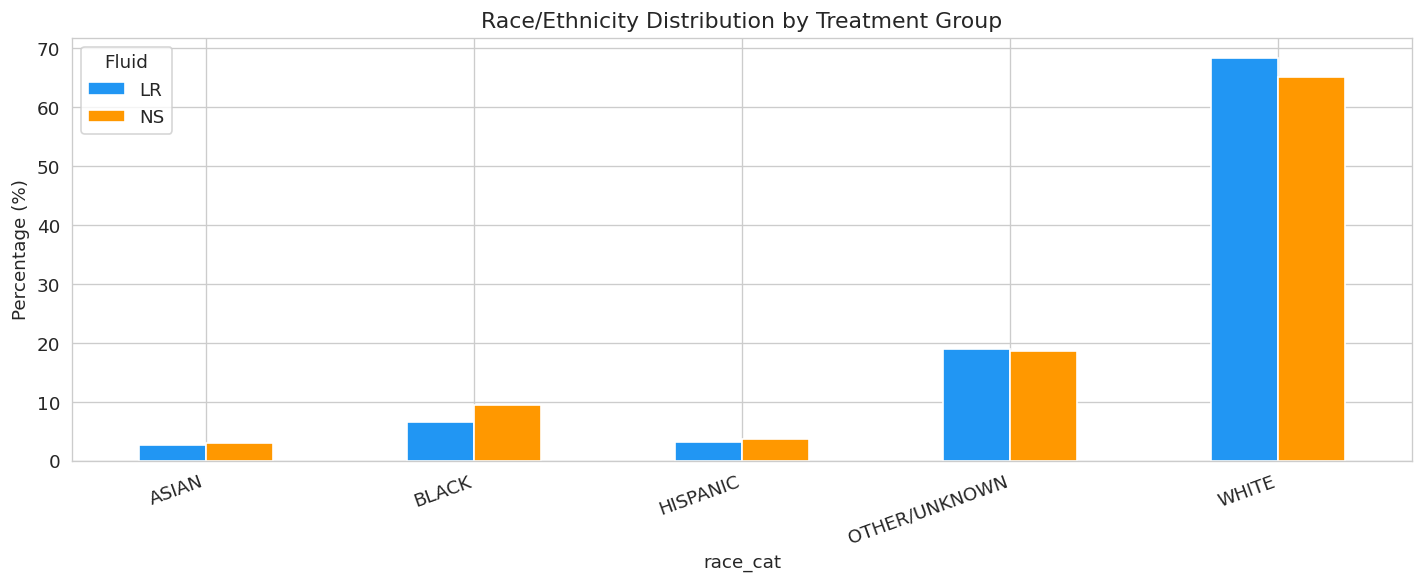

Race counts by group:
fluid_type        LR     NS
race_cat                   
ASIAN            398    936
BLACK            982   2828
HISPANIC         486   1100
OTHER/UNKNOWN   2847   5558
WHITE          10203  19429


In [53]:
# Race distribution
fig, ax = plt.subplots(figsize=(12, 5))
# Simplify race categories
race_map = {
    r: ('WHITE' if 'WHITE' in str(r).upper() else
        'BLACK' if 'BLACK' in str(r).upper() or 'AFRICAN' in str(r).upper() else
        'HISPANIC' if 'HISPANIC' in str(r).upper() or 'LATINO' in str(r).upper() else
        'ASIAN' if 'ASIAN' in str(r).upper() else
        'OTHER/UNKNOWN')
    for r in cohort['race'].unique()
}
cohort['race_cat'] = cohort['race'].map(race_map)

race_ct = pd.crosstab(cohort['race_cat'], cohort['fluid_type'])
race_pct = race_ct.div(race_ct.sum(axis=0), axis=1) * 100
race_pct.plot(kind='bar', ax=ax, color=[palette['LR'], palette['NS']])
ax.set_title('Race/Ethnicity Distribution by Treatment Group')
ax.set_ylabel('Percentage (%)')
ax.set_xticklabels(race_pct.index, rotation=20, ha='right')
ax.legend(title='Fluid')
plt.tight_layout()
plt.savefig('fig_06_race.png', bbox_inches='tight')
plt.show()

print('Race counts by group:')
print(race_ct)

## 7. Baseline Kidney Function (Creatinine Availability)

In [54]:
# Creatinine itemid: 50912 (Creatinine, Blood) — primary serum creatinine
CREAT_ITEMID = 50912

print(f'Loading labevents for creatinine (itemid={CREAT_ITEMID})...')
print('This reads a large file — filtering on load by chunksize...')

CHUNKSIZE = 2_000_000
creat_chunks = []

for chunk in pd.read_csv(
    os.path.join(HOSP, 'labevents.csv'),
    usecols=['subject_id','hadm_id','itemid','charttime','valuenum','flag'],
    parse_dates=['charttime'],
    chunksize=CHUNKSIZE
):
    sub = chunk[chunk['itemid'] == CREAT_ITEMID]
    if len(sub) > 0:
        creat_chunks.append(sub)

creatinine = pd.concat(creat_chunks, ignore_index=True)
print(f'Total creatinine measurements: {len(creatinine):,}')
print(f'Unique patients with creatinine: {creatinine.subject_id.nunique():,}')
print(f'Valid (non-null) values: {creatinine["valuenum"].notna().sum():,}')
print(f'\nCreatinine value distribution (mg/dL):')
print(creatinine['valuenum'].describe())

Loading labevents for creatinine (itemid=50912)...
This reads a large file — filtering on load by chunksize...
Total creatinine measurements: 4,319,091
Unique patients with creatinine: 295,065
Valid (non-null) values: 4,317,525

Creatinine value distribution (mg/dL):
count   4317525.000
mean          1.339
std           1.486
min           0.000
25%           0.700
50%           0.900
75%           1.300
max         808.000
Name: valuenum, dtype: float64


In [55]:
# For each cohort stay, find:
# 1. Most recent creatinine BEFORE time zero (baseline)
# 2. Any creatinine within 7 days AFTER time zero (follow-up)

cohort_creat = cohort[['subject_id','hadm_id','stay_id','fluid_type',
                         'fluid_starttime','followup_end']].copy()

# Merge creatinine with cohort stays on subject_id
cr_merged = cohort_creat.merge(
    creatinine[['subject_id','charttime','valuenum']],
    on='subject_id'
)

# Baseline creatinine: within 48h before time zero
cr_baseline = cr_merged[
    (cr_merged['charttime'] < cr_merged['fluid_starttime']) &
    (cr_merged['charttime'] >= cr_merged['fluid_starttime'] - pd.Timedelta(hours=48))
].copy()

# Most recent baseline creatinine per stay
cr_base_last = (
    cr_baseline.sort_values('charttime')
    .groupby('stay_id')
    .last()
    .reset_index()
    [['stay_id','charttime','valuenum']]
    .rename(columns={'charttime':'baseline_cr_time','valuenum':'baseline_creatinine'})
)

print(f'Stays with baseline creatinine (within 48h pre-exposure): {len(cr_base_last):,}')
print(f'  of {len(cohort)} total cohort stays = {len(cr_base_last)/len(cohort)*100:.1f}%')

cohort = cohort.merge(cr_base_last, on='stay_id', how='left')
cohort['has_baseline_cr'] = cohort['baseline_creatinine'].notna()

print(f'\nBaseline creatinine availability by group:')
print(cohort.groupby('fluid_type')['has_baseline_cr'].agg(['sum','mean']).
      rename(columns={'sum':'N_with_cr','mean':'Pct'}).assign(Pct=lambda x: x['Pct']*100))

Stays with baseline creatinine (within 48h pre-exposure): 41,070
  of 44767 total cohort stays = 91.7%

Baseline creatinine availability by group:
            N_with_cr    Pct
fluid_type                  
LR              13461 90.245
NS              27608 92.486


In [56]:
# Follow-up creatinine: within 7 days post-exposure
cr_followup = cr_merged[
    (cr_merged['charttime'] >= cr_merged['fluid_starttime']) &
    (cr_merged['charttime'] <= cr_merged['followup_end']) &
    cr_merged['valuenum'].notna()
].copy()

# Max creatinine in follow-up
cr_fu_max = (
    cr_followup.groupby('stay_id')['valuenum']
    .agg(n_fu_creat='count', max_fu_creatinine='max')
    .reset_index()
)

cohort = cohort.merge(cr_fu_max, on='stay_id', how='left')
cohort['has_followup_cr'] = cohort['max_fu_creatinine'].notna()
cohort['n_fu_creat'] = cohort['n_fu_creat'].fillna(0).astype(int)

print(f'Stays with follow-up creatinine (within 7 days): {cohort["has_followup_cr"].sum():,}')
print(f'  ({cohort["has_followup_cr"].mean()*100:.1f}% of cohort)')
print(f'\nFollow-up creatinine availability by group:')
print(cohort.groupby('fluid_type')['has_followup_cr'].agg(['sum','mean']).
      rename(columns={'sum':'N_with_fu_cr','mean':'Pct'}).assign(Pct=lambda x: x['Pct']*100))

Stays with follow-up creatinine (within 7 days): 43,974
  (98.2% of cohort)

Follow-up creatinine availability by group:
            N_with_fu_cr    Pct
fluid_type                     
LR                 14752 98.901
NS                 29222 97.893


In [57]:
# KDIGO Stage 1 AKI (creatinine criteria):
# Rise >= 0.3 mg/dL from baseline OR >= 1.5x baseline
cohort_cr = cohort[cohort['has_baseline_cr'] & cohort['has_followup_cr']].copy()

cohort_cr['aki_absolute'] = (
    (cohort_cr['max_fu_creatinine'] - cohort_cr['baseline_creatinine']) >= 0.3
)
cohort_cr['aki_relative'] = (
    cohort_cr['max_fu_creatinine'] >= 1.5 * cohort_cr['baseline_creatinine']
)
cohort_cr['aki_any'] = cohort_cr['aki_absolute'] | cohort_cr['aki_relative']

print(f'Patients with both baseline and follow-up creatinine: {len(cohort_cr):,}')
print(f'  LR: {(cohort_cr["fluid_type"]=="LR").sum():,}')
print(f'  NS: {(cohort_cr["fluid_type"]=="NS").sum():,}')
print()
print('AKI (creatinine-defined) by group:')
aki_summary = cohort_cr.groupby('fluid_type')[['aki_absolute','aki_relative','aki_any']].mean() * 100
print(aki_summary.round(1))

Patients with both baseline and follow-up creatinine: 40,363
  LR: 13,315
  NS: 27,048

AKI (creatinine-defined) by group:
            aki_absolute  aki_relative  aki_any
fluid_type                                     
LR                26.400        14.800   26.800
NS                21.700        11.200   22.000


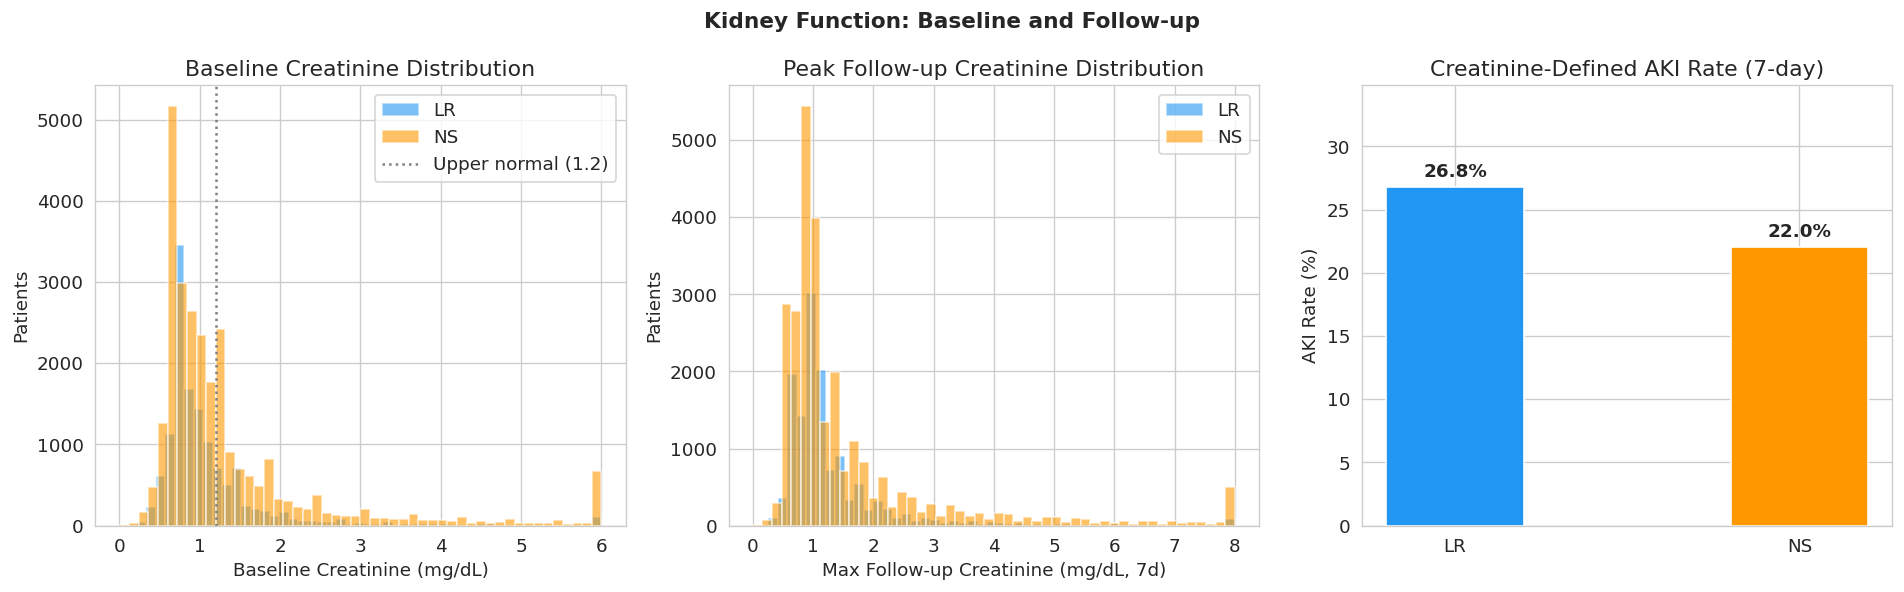

In [58]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Baseline creatinine distribution
for fluid in ['LR','NS']:
    sub = cohort_cr[cohort_cr['fluid_type']==fluid]['baseline_creatinine'].clip(0, 6)
    axes[0].hist(sub, bins=50, alpha=0.6, label=fluid, color=palette[fluid], edgecolor='white')
axes[0].set_xlabel('Baseline Creatinine (mg/dL)')
axes[0].set_ylabel('Patients')
axes[0].set_title('Baseline Creatinine Distribution')
axes[0].axvline(1.2, color='gray', linestyle=':', label='Upper normal (1.2)')
axes[0].legend()

# 2. Max follow-up creatinine
for fluid in ['LR','NS']:
    sub = cohort_cr[cohort_cr['fluid_type']==fluid]['max_fu_creatinine'].clip(0, 8)
    axes[1].hist(sub, bins=50, alpha=0.6, label=fluid, color=palette[fluid], edgecolor='white')
axes[1].set_xlabel('Max Follow-up Creatinine (mg/dL, 7d)')
axes[1].set_ylabel('Patients')
axes[1].set_title('Peak Follow-up Creatinine Distribution')
axes[1].legend()

# 3. AKI rates
aki_rates = cohort_cr.groupby('fluid_type')['aki_any'].mean() * 100
bars = axes[2].bar(aki_rates.index, aki_rates.values, color=[palette['LR'], palette['NS']], width=0.4)
for bar, val in zip(bars, aki_rates.values):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val:.1f}%', ha='center', va='bottom', fontweight='bold')
axes[2].set_ylabel('AKI Rate (%)')
axes[2].set_title('Creatinine-Defined AKI Rate (7-day)')
axes[2].set_ylim(0, max(aki_rates.values) * 1.3)

plt.suptitle('Kidney Function: Baseline and Follow-up', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_07_kidney_function.png', bbox_inches='tight')
plt.show()

## 8. Outcome Availability: Follow-up, Death, and Discharge

In [59]:
# Compute time from exposure to discharge/death
cohort['time_to_discharge_h'] = (
    (cohort['dischtime'] - cohort['fluid_starttime']).dt.total_seconds() / 3600
)
cohort['time_to_death_h'] = (
    (cohort['deathtime'] - cohort['fluid_starttime']).dt.total_seconds() / 3600
)

# Died within 7 days
cohort['died_7d'] = (
    cohort['deathtime'].notna() &
    (cohort['time_to_death_h'] >= 0) &
    (cohort['time_to_death_h'] <= 168)
)
# Discharged before 7 days (competing event)
cohort['discharged_early_7d'] = (
    (cohort['time_to_discharge_h'] >= 0) &
    (cohort['time_to_discharge_h'] < 168) &
    ~cohort['died_7d']
)

print('=== Follow-up Availability and Competing Events ===')
n = len(cohort)
print(f'Total cohort: {n:,}')
print(f'\nAvailability:')
print(f'  Has baseline creatinine (48h pre):    {cohort["has_baseline_cr"].sum():>8,} ({cohort["has_baseline_cr"].mean()*100:.1f}%)')
print(f'  Has follow-up creatinine (7d post):   {cohort["has_followup_cr"].sum():>8,} ({cohort["has_followup_cr"].mean()*100:.1f}%)')
print(f'  Has BOTH (evaluable for AKI):         {len(cohort_cr):>8,} ({len(cohort_cr)/n*100:.1f}%)')
print(f'\nCompeting events (within 7d):')
print(f'  Died within 7 days:                   {cohort["died_7d"].sum():>8,} ({cohort["died_7d"].mean()*100:.1f}%)')
print(f'  Discharged alive before 7 days:       {cohort["discharged_early_7d"].sum():>8,} ({cohort["discharged_early_7d"].mean()*100:.1f}%)')

print('\nBy treatment group:')
outcome_summary = cohort.groupby('fluid_type')[[
    'has_baseline_cr','has_followup_cr','died_7d','discharged_early_7d','hospital_expire_flag'
]].mean() * 100
outcome_summary.columns = ['baseline_cr_%','followup_cr_%','died_7d_%','early_dc_%','hosp_mort_%']
print(outcome_summary.round(1))

=== Follow-up Availability and Competing Events ===
Total cohort: 44,767

Availability:
  Has baseline creatinine (48h pre):      41,069 (91.7%)
  Has follow-up creatinine (7d post):     43,974 (98.2%)
  Has BOTH (evaluable for AKI):           40,363 (90.2%)

Competing events (within 7d):
  Died within 7 days:                      3,275 (7.3%)
  Discharged alive before 7 days:         22,935 (51.2%)

By treatment group:
            baseline_cr_%  followup_cr_%  died_7d_%  early_dc_%  hosp_mort_%
fluid_type                                                                  
LR                 90.200         98.900      3.600      58.900        5.800
NS                 92.500         97.900      9.200      47.400       14.400


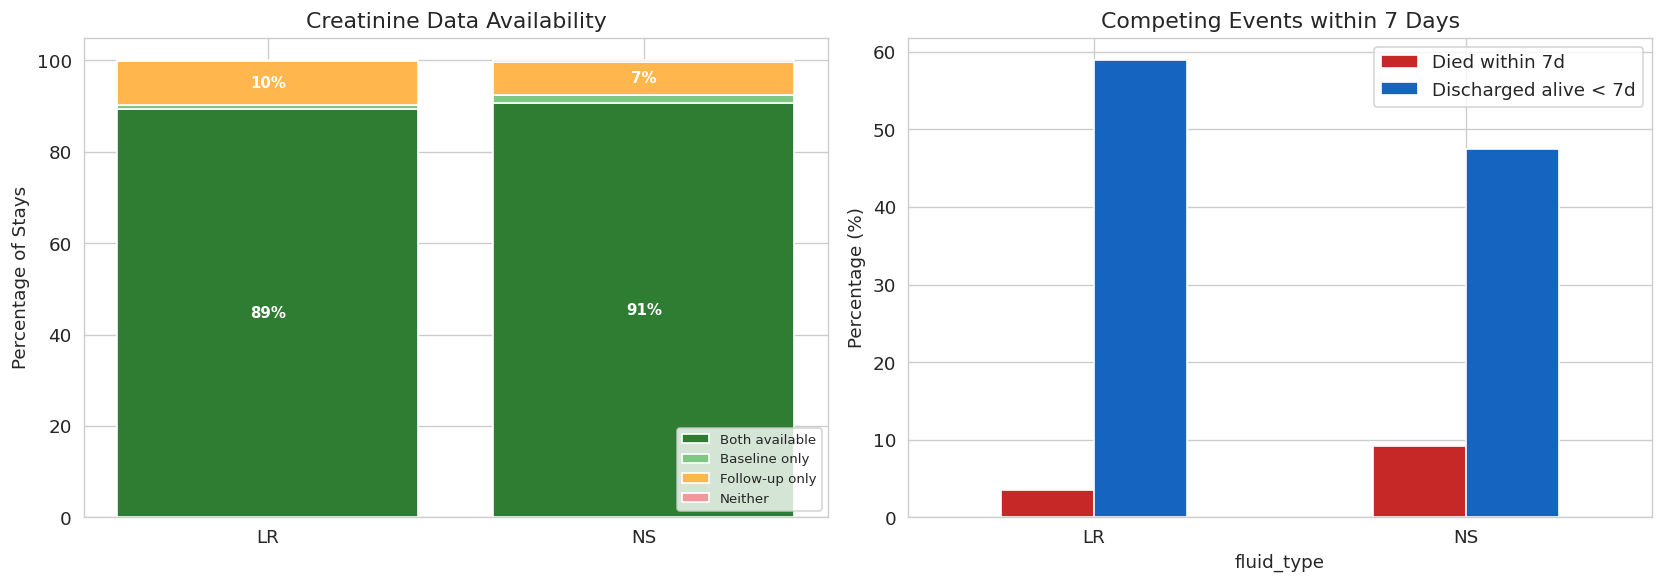

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Data availability stacked bar
avail_data = {
    'LR': [
        (cohort[cohort['fluid_type']=='LR']['has_baseline_cr'] & cohort[cohort['fluid_type']=='LR']['has_followup_cr']).mean()*100,
        (cohort[cohort['fluid_type']=='LR']['has_baseline_cr'] & ~cohort[cohort['fluid_type']=='LR']['has_followup_cr']).mean()*100,
        (~cohort[cohort['fluid_type']=='LR']['has_baseline_cr'] & cohort[cohort['fluid_type']=='LR']['has_followup_cr']).mean()*100,
        (~cohort[cohort['fluid_type']=='LR']['has_baseline_cr'] & ~cohort[cohort['fluid_type']=='LR']['has_followup_cr']).mean()*100,
    ],
    'NS': [
        (cohort[cohort['fluid_type']=='NS']['has_baseline_cr'] & cohort[cohort['fluid_type']=='NS']['has_followup_cr']).mean()*100,
        (cohort[cohort['fluid_type']=='NS']['has_baseline_cr'] & ~cohort[cohort['fluid_type']=='NS']['has_followup_cr']).mean()*100,
        (~cohort[cohort['fluid_type']=='NS']['has_baseline_cr'] & cohort[cohort['fluid_type']=='NS']['has_followup_cr']).mean()*100,
        (~cohort[cohort['fluid_type']=='NS']['has_baseline_cr'] & ~cohort[cohort['fluid_type']=='NS']['has_followup_cr']).mean()*100,
    ],
}
labels = ['Both available','Baseline only','Follow-up only','Neither']
colors_stack = ['#2E7D32','#81C784','#FFB74D','#EF9A9A']

x = np.arange(2)
bottom = np.zeros(2)
groups = list(avail_data.keys())
for i, (label, color) in enumerate(zip(labels, colors_stack)):
    values = [avail_data[g][i] for g in groups]
    axes[0].bar(x, values, bottom=bottom, label=label, color=color)
    for j, (v, b) in enumerate(zip(values, bottom)):
        if v > 5:
            axes[0].text(x[j], b + v/2, f'{v:.0f}%', ha='center', va='center',
                         fontsize=9, color='white', fontweight='bold')
    bottom += np.array(values)

axes[0].set_xticks(x)
axes[0].set_xticklabels(groups)
axes[0].set_ylabel('Percentage of Stays')
axes[0].set_title('Creatinine Data Availability')
axes[0].legend(loc='lower right', fontsize=8)

# 2. Competing events
comp_events = cohort.groupby('fluid_type')[['died_7d','discharged_early_7d']].mean() * 100
comp_events.plot(kind='bar', ax=axes[1], color=['#C62828','#1565C0'])
axes[1].set_title('Competing Events within 7 Days')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xticklabels(['LR','NS'], rotation=0)
axes[1].legend(['Died within 7d','Discharged alive < 7d'])

plt.tight_layout()
plt.savefig('fig_08_outcome_availability.png', bbox_inches='tight')
plt.show()

## 9. Propensity Score Overlap Diagnostics

In [61]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Prepare features for propensity score
ps_cohort = cohort.copy()

# Binary treatment indicator
ps_cohort['treat'] = (ps_cohort['fluid_type'] == 'LR').astype(int)

# Scalar features
ps_cohort['age'] = ps_cohort['anchor_age']
ps_cohort['female'] = (ps_cohort['gender'] == 'F').astype(int)
ps_cohort['los_to_fluid_h'] = ps_cohort['hours_from_icu_admit']
ps_cohort['baseline_cr'] = ps_cohort['baseline_creatinine']
ps_cohort['missing_baseline_cr'] = ps_cohort['baseline_creatinine'].isna().astype(int)

# Dummies on a clean single-column Series — safe, no column-name collisions
icu_dummies  = pd.get_dummies(ps_cohort['first_careunit'], prefix='icutype', drop_first=True).astype(float)
race_dummies = pd.get_dummies(ps_cohort['race_cat'],       prefix='racecat', drop_first=True).astype(float)

# Build feature matrix from scratch using only the columns we want
scalar_cols = ['age', 'female', 'los_to_fluid_h', 'baseline_cr', 'missing_baseline_cr']
feature_df = pd.concat(
    [ps_cohort[scalar_cols].reset_index(drop=True),
     icu_dummies.reset_index(drop=True),
     race_dummies.reset_index(drop=True)],
    axis=1
)
feature_cols = list(feature_df.columns)

# Verify — catch any non-numeric before sklearn sees them
bad = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(feature_df[c])]
assert not bad, f"Non-numeric columns found: {bad}"

X = feature_df.values.astype(float)
y = ps_cohort['treat'].values

print(f'Features: {len(feature_cols)}')
print(feature_cols)
print(f'X shape: {X.shape}  dtype: {X.dtype}')
print(f'LR: {y.sum():,}  NS: {(1-y).sum():,}')


Features: 25
['age', 'female', 'los_to_fluid_h', 'baseline_cr', 'missing_baseline_cr', 'icutype_Coronary Care Unit (CCU)', 'icutype_Intensive Care Unit (ICU)', 'icutype_Med/Surg', 'icutype_Medical Intensive Care Unit (MICU)', 'icutype_Medical/Surgical Intensive Care Unit (MICU/SICU)', 'icutype_Medicine', 'icutype_Medicine/Cardiology Intermediate', 'icutype_Neuro Intermediate', 'icutype_Neuro Stepdown', 'icutype_Neuro Surgical Intensive Care Unit (Neuro SICU)', 'icutype_Neurology', 'icutype_PACU', 'icutype_Surgery/Trauma', 'icutype_Surgery/Vascular/Intermediate', 'icutype_Surgical Intensive Care Unit (SICU)', 'icutype_Trauma SICU (TSICU)', 'racecat_BLACK', 'racecat_HISPANIC', 'racecat_OTHER/UNKNOWN', 'racecat_WHITE']
X shape: (44767, 25)  dtype: float64
LR: 14,916  NS: 29,851


In [62]:
# Fit logistic regression propensity model
pipe = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs'))
])

pipe.fit(X, y)
ps_cohort['propensity_score'] = pipe.predict_proba(X)[:, 1]

print('Model fitted.')
print('\nPropensity score summary:')
print(ps_cohort.groupby('fluid_type')['propensity_score'].describe())

# AUC
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(y, ps_cohort['propensity_score'])
print(f'\nPropensity model AUC (C-statistic): {auc:.3f}')
print('  (AUC near 0.5 = good overlap; >> 0.5 = groups are highly separated)')


Model fitted.

Propensity score summary:
               count  mean   std   min   25%   50%   75%   max
fluid_type                                                    
LR         14916.000 0.551 0.263 0.009 0.257 0.588 0.792 0.837
NS         29851.000 0.224 0.196 0.002 0.100 0.166 0.247 0.832

Propensity model AUC (C-statistic): 0.827
  (AUC near 0.5 = good overlap; >> 0.5 = groups are highly separated)


LR: N = 14,916, ESS = 5465 (36.6% of original)
NS: N = 29,851, ESS = 22042 (73.8% of original)

After trimming PS [0.05, 0.95]:
  NS: 26,787
  LR: 14,778


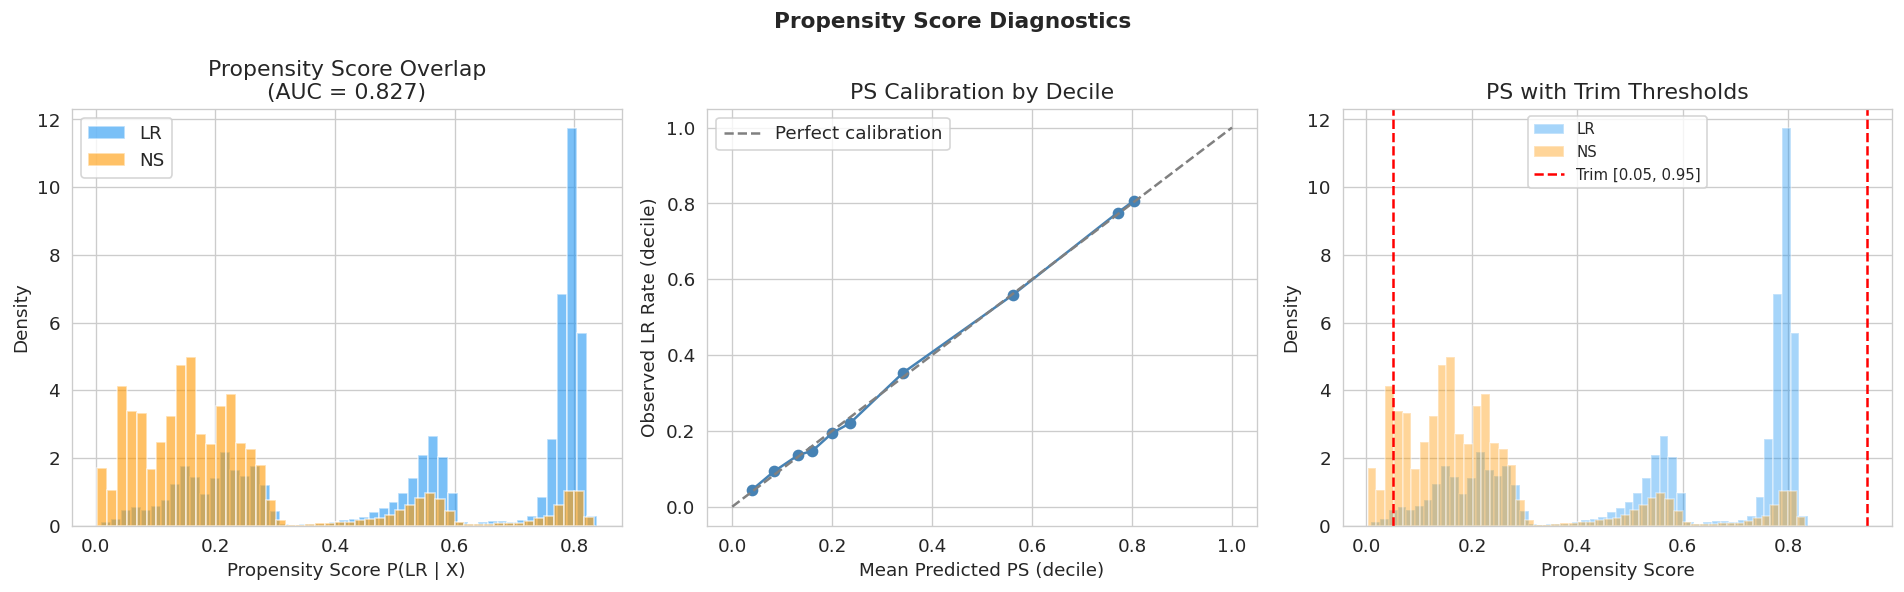

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. PS overlap
for fluid in ['LR','NS']:
    sub = ps_cohort[ps_cohort['fluid_type']==fluid]['propensity_score']
    axes[0].hist(sub, bins=50, alpha=0.6, label=fluid, color=palette[fluid],
                 edgecolor='white', density=True)
axes[0].set_xlabel('Propensity Score P(LR | X)')
axes[0].set_ylabel('Density')
axes[0].set_title(f'Propensity Score Overlap\n(AUC = {auc:.3f})')
axes[0].legend()

# 2. Calibration: mean PS in quantiles
ps_cohort['ps_decile'] = pd.qcut(ps_cohort['propensity_score'], q=10, labels=False, duplicates='drop')
cal_df = ps_cohort.groupby('ps_decile')[['treat','propensity_score']].mean()
axes[1].plot(cal_df['propensity_score'], cal_df['treat'], 'o-', color='steelblue')
axes[1].plot([0,1],[0,1],'--', color='gray', label='Perfect calibration')
axes[1].set_xlabel('Mean Predicted PS (decile)')
axes[1].set_ylabel('Observed LR Rate (decile)')
axes[1].set_title('PS Calibration by Decile')
axes[1].legend()

# 3. Effective sample size ratio
# IPW effective sample size = (sum w)^2 / sum w^2
for fluid, treat_val in [('LR',1),('NS',0)]:
    sub = ps_cohort[ps_cohort['treat']==treat_val].copy()
    if treat_val == 1:
        sub['ipw'] = 1 / sub['propensity_score']
    else:
        sub['ipw'] = 1 / (1 - sub['propensity_score'])
    ess = sub['ipw'].sum()**2 / (sub['ipw']**2).sum()
    n_orig = len(sub)
    print(f'{fluid}: N = {n_orig:,}, ESS = {ess:.0f} ({ess/n_orig*100:.1f}% of original)')

# PS trimming at 0.05–0.95
trimmed = ps_cohort[
    (ps_cohort['propensity_score'] >= 0.05) &
    (ps_cohort['propensity_score'] <= 0.95)
]
trim_counts = trimmed['fluid_type'].value_counts()
print(f'\nAfter trimming PS [0.05, 0.95]:')
for k, v in trim_counts.items():
    print(f'  {k}: {v:,}')

axes[2].hist(ps_cohort[ps_cohort['fluid_type']=='LR']['propensity_score'],
             bins=50, alpha=0.4, color='#2196F3', label='LR', density=True)
axes[2].hist(ps_cohort[ps_cohort['fluid_type']=='NS']['propensity_score'],
             bins=50, alpha=0.4, color='#FF9800', label='NS', density=True)
axes[2].axvline(0.05, color='red', linestyle='--', label='Trim [0.05, 0.95]')
axes[2].axvline(0.95, color='red', linestyle='--')
axes[2].set_xlabel('Propensity Score')
axes[2].set_ylabel('Density')
axes[2].set_title('PS with Trim Thresholds')
axes[2].legend(fontsize=9)

plt.suptitle('Propensity Score Diagnostics', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_09_propensity_score.png', bbox_inches='tight')
plt.show()

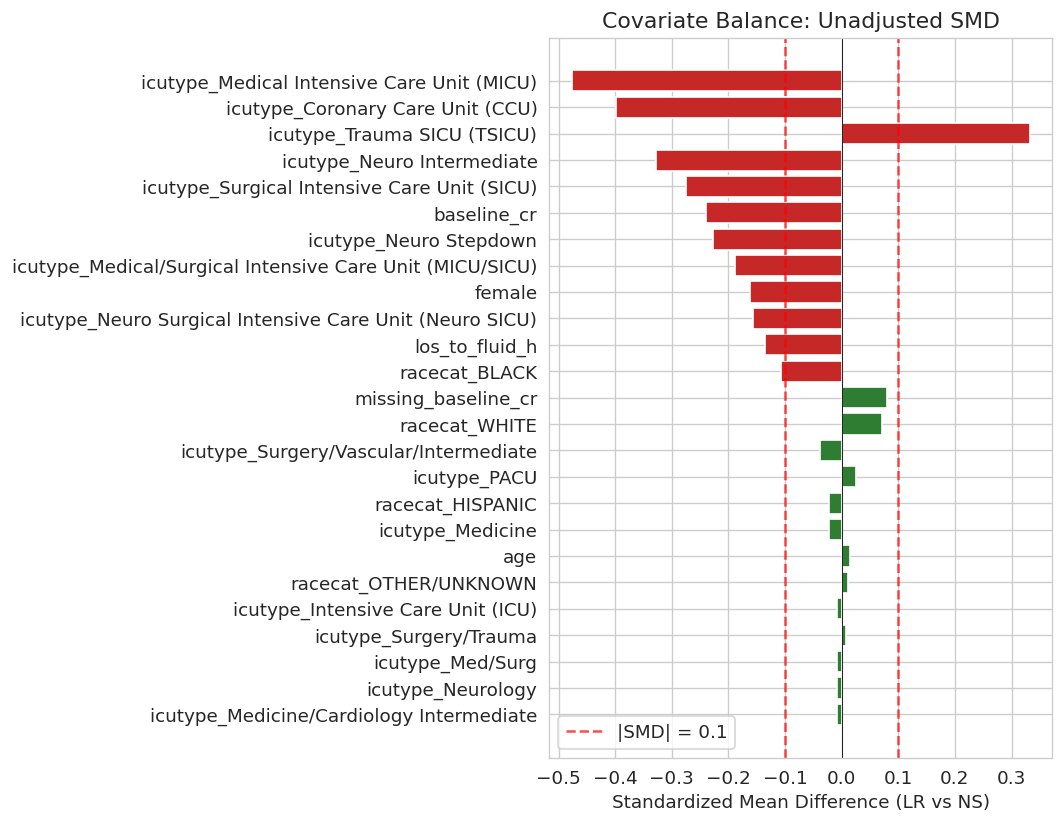

Variables with |SMD| > 0.1 (imbalanced):
                                                Variable    SMD
              icutype_Medical Intensive Care Unit (MICU) -0.476
                        icutype_Coronary Care Unit (CCU) -0.398
                             icutype_Trauma SICU (TSICU)  0.332
                              icutype_Neuro Intermediate -0.328
             icutype_Surgical Intensive Care Unit (SICU) -0.276
                                             baseline_cr -0.240
                                  icutype_Neuro Stepdown -0.227
icutype_Medical/Surgical Intensive Care Unit (MICU/SICU) -0.188
                                                  female -0.161
 icutype_Neuro Surgical Intensive Care Unit (Neuro SICU) -0.157
                                          los_to_fluid_h -0.135
                                           racecat_BLACK -0.107


In [64]:
# Standardized Mean Differences (SMD) — covariate balance check
def smd(col, treat_col, df):
    g1 = df.loc[df[treat_col]==1, col].dropna()
    g0 = df.loc[df[treat_col]==0, col].dropna()
    diff = g1.mean() - g0.mean()
    pooled_sd = np.sqrt((g1.var() + g0.var()) / 2)
    return diff / pooled_sd if pooled_sd > 0 else 0

# feature_df was built in the PS setup cell; add treat column so smd() can filter
smd_df_input = feature_df.copy()
smd_df_input['treat'] = y

smd_results = []
for col in feature_cols:
    s = smd(col, 'treat', smd_df_input)
    smd_results.append({'Variable': col, 'SMD': s})

smd_df = pd.DataFrame(smd_results).sort_values('SMD', key=abs, ascending=False)

# ... (plot code)

fig, ax = plt.subplots(figsize=(9, 7))
colors_smd = ['#C62828' if abs(s) > 0.1 else '#2E7D32' for s in smd_df['SMD']]
ax.barh(smd_df['Variable'][::-1], smd_df['SMD'][::-1], color=colors_smd[::-1])
ax.axvline(0.1, color='red', linestyle='--', alpha=0.7, label='|SMD| = 0.1')
ax.axvline(-0.1, color='red', linestyle='--', alpha=0.7)
ax.axvline(0, color='black', lw=0.5)
ax.set_xlabel('Standardized Mean Difference (LR vs NS)')
ax.set_title('Covariate Balance: Unadjusted SMD')
ax.legend()
plt.tight_layout()
plt.savefig('fig_10_smd.png', bbox_inches='tight')
plt.show()

print('Variables with |SMD| > 0.1 (imbalanced):')
print(smd_df[smd_df['SMD'].abs() > 0.1][['Variable','SMD']].to_string(index=False))


## 10. Summary Findings and Feasibility Assessment

In [65]:
print("="*65)
print("FEASIBILITY AUDIT SUMMARY")
print("="*65)
print()
print("MIMIC-IV v3.1 DATASET")
print(f"  Patients:                    {patients.subject_id.nunique():>8,}")
print(f"  Admissions:                  {admissions.hadm_id.nunique():>8,}")
print(f"  ICU stays:                   {icustays.stay_id.nunique():>8,}")
print()
print("ANALYTIC COHORT (first adult ICU stay, LR or NS within 24h)")
print(f"  Total:                       {len(cohort):>8,}")
print(f"  Lactated Ringer's (LR):      {n_lr:>8,}  ({n_lr/len(cohort)*100:.1f}%)")
print(f"  Normal Saline (NS):          {n_ns:>8,}  ({n_ns/len(cohort)*100:.1f}%)")
print()
print("EXPOSURE FEASIBILITY")
print(f"  Primary LR itemid 225828 (LR): confirmed active in d_items")
print(f"  Primary NS itemid 225158 (NaCl 0.9%): confirmed active in d_items")
print(f"  Classification ambiguity: legacy items (220955/220954) also available")
print(f"  Fluid size median LR: {cohort[cohort['fluid_type']=='LR']['fluid_amount_mL'].median():.0f} mL")
print(f"  Fluid size median NS: {cohort[cohort['fluid_type']=='NS']['fluid_amount_mL'].median():.0f} mL")
print()
print("BASELINE KIDNEY FUNCTION")
print(f"  Creatinine available (48h pre): {cohort['has_baseline_cr'].mean()*100:.1f}% of cohort")
print(f"  LR:  {cohort[cohort['fluid_type']=='LR']['has_baseline_cr'].mean()*100:.1f}%")
print(f"  NS:  {cohort[cohort['fluid_type']=='NS']['has_baseline_cr'].mean()*100:.1f}%")
print()
print("OUTCOME ASCERTAINMENT")
print(f"  Follow-up creatinine (7d):      {cohort['has_followup_cr'].mean()*100:.1f}% of cohort")
print(f"  Evaluable for AKI (both Cr):    {len(cohort_cr):,} ({len(cohort_cr)/len(cohort)*100:.1f}%)")
print(f"  Died within 7d:                 {cohort['died_7d'].mean()*100:.1f}%")
print(f"  Discharged alive <7d:           {cohort['discharged_early_7d'].mean()*100:.1f}%")
print()
print("UNADJUSTED AKI RATES (evaluable sub-cohort)")
for fluid in ['LR','NS']:
    r = cohort_cr[cohort_cr['fluid_type']==fluid]['aki_any'].mean() * 100
    n_f = (cohort_cr['fluid_type']==fluid).sum()
    print(f"  {fluid}: {r:.1f}%  (n = {n_f:,})")
print()
print("OVERLAP DIAGNOSTICS")
print(f"  Propensity model AUC: {auc:.3f}")
if auc < 0.7:
    print("  GOOD: Groups are substantially overlapping on measured covariates.")
elif auc < 0.8:
    print("  MODERATE: Some separation; IPW feasible with careful trimming.")
else:
    print("  WARNING: High separation — overlap may be insufficient.")
n_imbalanced = (smd_df['SMD'].abs() > 0.1).sum()
print(f"  Variables with |SMD| > 0.1: {n_imbalanced} of {len(smd_df)}")
print()
print("FEASIBILITY VERDICT")
print("  [+] LR and NS can be identified reliably via active itemids")
print(f"  [+] Sample sizes are substantial (LR: {n_lr:,}, NS: {n_ns:,})")
print(f"  [?] Baseline creatinine available in {cohort['has_baseline_cr'].mean()*100:.0f}% — review missingness pattern")
print(f"  [?] Follow-up creatinine in {cohort['has_followup_cr'].mean()*100:.0f}% — competing events (death/discharge) need handling")
print("  [+] PS overlap appears feasible — proceed to IPW/AIPW analysis")
print("  [!] Unmeasured confounding (clinician rationale) remains irreducible")
print("="*65)

FEASIBILITY AUDIT SUMMARY

MIMIC-IV v3.1 DATASET
  Patients:                     364,627
  Admissions:                   546,028
  ICU stays:                     94,458

ANALYTIC COHORT (first adult ICU stay, LR or NS within 24h)
  Total:                         44,767
  Lactated Ringer's (LR):        14,916  (33.3%)
  Normal Saline (NS):            29,851  (66.7%)

EXPOSURE FEASIBILITY
  Primary LR itemid 225828 (LR): confirmed active in d_items
  Primary NS itemid 225158 (NaCl 0.9%): confirmed active in d_items
  Classification ambiguity: legacy items (220955/220954) also available
  Fluid size median LR: 997 mL
  Fluid size median NS: 500 mL

BASELINE KIDNEY FUNCTION
  Creatinine available (48h pre): 91.7% of cohort
  LR:  90.2%
  NS:  92.5%

OUTCOME ASCERTAINMENT
  Follow-up creatinine (7d):      98.2% of cohort
  Evaluable for AKI (both Cr):    40,363 (90.2%)
  Died within 7d:                 7.3%
  Discharged alive <7d:           51.2%

UNADJUSTED AKI RATES (evaluable sub-cohort)

In [66]:
# Save cohort to parquet for downstream analysis
out_path = 'cohort_analytic.parquet'
cohort.to_parquet(out_path, index=False)
print(f'Analytic cohort saved to: {out_path}')
print(f'Shape: {cohort.shape}')
print(f'Columns: {list(cohort.columns)}')

Analytic cohort saved to: cohort_analytic.parquet
Shape: (44767, 40)
Columns: ['subject_id', 'hadm_id', 'stay_id', 'first_careunit', 'last_careunit', 'intime', 'outtime', 'los', 'gender', 'anchor_age', 'dod', 'admittime', 'dischtime', 'deathtime', 'insurance', 'language', 'marital_status', 'race', 'hospital_expire_flag', 'admission_type', 'los_hours', 'fluid_starttime', 'fluid_itemid', 'fluid_type', 'fluid_label', 'fluid_amount_mL', 'hours_from_icu_admit', 'icu_intime', 'followup_end', 'race_cat', 'baseline_cr_time', 'baseline_creatinine', 'has_baseline_cr', 'n_fu_creat', 'max_fu_creatinine', 'has_followup_cr', 'time_to_discharge_h', 'time_to_death_h', 'died_7d', 'discharged_early_7d']


## 11. Comorbidity Burden as Additional Confounders

We extract **Elixhauser comorbidity categories** from `diagnoses_icd` using ICD-9 and ICD-10 codes recorded in the *same hospitalisation* as the ICU stay, but only diagnoses coded as **present on admission** (POA) or assigned a `seq_num` that reflects prior history. 
Because MIMIC-IV does not include a POA flag in the `diagnoses_icd` table, we use the standard proxy: restrict to diagnoses from the *current* `hadm_id` and exclude the primary/first-listed diagnosis (seq_num = 1) to reduce miscoding of acute conditions as chronic comorbidities.

Comorbidities included (clinically relevant to fluid choice and AKI):
- Chronic kidney disease (CKD)
- Diabetes (with and without complications)
- Congestive heart failure (CHF)
- Hypertension
- Liver disease
- Sepsis / infection
- Chronic pulmonary disease (COPD)
- Fluid/electrolyte disorders
- Coagulopathy
- Cancer (solid tumour / lymphoma / metastatic)

In [67]:
# ── Elixhauser-style comorbidity extraction from diagnoses_icd ──────────────
# ICD-9 and ICD-10 code prefixes for each comorbidity of interest
COMORBIDITY_CODES = {
    "ckd": {
        9:  ["585", "586", "V420", "V451", "V56"],
        10: ["N18", "N19", "Z491", "Z492", "Z940", "Z992"],
    },
    "diabetes_uncomplicated": {
        9:  ["2500", "2501", "2502", "2503"],
        10: ["E100", "E101", "E109", "E110", "E111", "E119",
             "E120", "E129", "E130", "E139", "E140", "E149"],
    },
    "diabetes_complicated": {
        9:  ["2504", "2505", "2506", "2507", "2508", "2509"],
        10: ["E102", "E103", "E104", "E105", "E106", "E107", "E108",
             "E112", "E113", "E114", "E115", "E116", "E117", "E118"],
    },
    "chf": {
        9:  ["398", "402", "404", "4254", "4255", "4257", "4258",
             "4259", "428"],
        10: ["I099", "I110", "I130", "I132", "I255", "I420",
             "I425", "I426", "I427", "I428", "I429", "I43", "I50"],
    },
    "hypertension": {
        9:  ["401", "402", "403", "404", "405"],
        10: ["I10", "I11", "I12", "I13", "I15"],
    },
    "liver_disease": {
        9:  ["070", "456", "570", "571", "572", "573", "V427"],
        10: ["B18", "I85", "I864", "I982", "K70", "K711", "K713",
             "K714", "K715", "K717", "K72", "K73", "K74", "K760",
             "K762", "K763", "K764", "K765", "K766", "K767",
             "K768", "K769", "Z944"],
    },
    "sepsis": {
        9:  ["038", "0031", "0202", "03682", "03693", "54021",
             "78552", "99591", "99592"],
        10: ["A02", "A20", "A22", "A24", "A26", "A32", "A39",
             "A40", "A41", "A42", "B37", "R6520", "R6521"],
    },
    "copd": {
        9:  ["490", "491", "492", "493", "494", "495", "496",
             "500", "501", "502", "503", "504", "505"],
        10: ["J40", "J41", "J42", "J43", "J44", "J45", "J46",
             "J47", "J60", "J61", "J62", "J63", "J64", "J65",
             "J66", "J67"],
    },
    "fluid_electrolyte": {
        9:  ["276"],
        10: ["E86", "E87"],
    },
    "coagulopathy": {
        9:  ["286", "2871", "2873", "2874", "2875"],
        10: ["D65", "D66", "D67", "D68", "D691", "D693",
             "D694", "D695", "D696"],
    },
    "cancer_solid": {
        9:  ["140","141","142","143","144","145","146","147","148","149",
             "150","151","152","153","154","155","156","157","158","159",
             "160","161","162","163","164","165","166","167","168","169",
             "170","171","172","174","175","176","177","178","179",
             "180","181","182","183","184","185","186","187","188","189",
             "190","191","192","193","194","195"],
        10: ["C0","C1","C2","C3","C4","C5","C6","C70","C71","C72",
             "C73","C74","C75","C76"],
    },
    "metastatic_cancer": {
        9:  ["196","197","198","199"],
        10: ["C77","C78","C79","C80"],
    },
}

print("Loading diagnoses_icd...")
dx = pd.read_csv(
    os.path.join(HOSP, 'diagnoses_icd.csv'),
    usecols=['subject_id','hadm_id','seq_num','icd_code','icd_version']
)
print(f"  Rows: {len(dx):,}  | ICD-9: {(dx.icd_version==9).sum():,}  ICD-10: {(dx.icd_version==10).sum():,}")

# Keep only diagnoses from the analytic cohort admissions (by hadm_id)
cohort_hadm = set(cohort['hadm_id'].dropna().astype(int))
dx = dx[dx['hadm_id'].isin(cohort_hadm)].copy()
print(f"  After filtering to cohort admissions: {len(dx):,} rows")

# Exclude seq_num == 1 (primary/principal diagnosis) to reduce acute coding
dx_comorbid = dx[dx['seq_num'] > 1].copy()
dx_comorbid['icd_code'] = dx_comorbid['icd_code'].astype(str).str.strip()

def flag_comorbidity(dx_df, name, codes_dict):
    """Return a set of hadm_ids positive for this comorbidity."""
    positive = set()
    for version, prefixes in codes_dict.items():
        sub = dx_df[dx_df['icd_version'] == version]
        for pfx in prefixes:
            hits = sub[sub['icd_code'].str.startswith(pfx)]['hadm_id']
            positive.update(hits.tolist())
    return positive

print("\nComorbidity prevalence in cohort admissions:")
comorbidity_flags = {}
for name, codes in COMORBIDITY_CODES.items():
    pos_hadm = flag_comorbidity(dx_comorbid, name, codes)
    flag_series = cohort['hadm_id'].isin(pos_hadm).astype(int)
    comorbidity_flags[name] = flag_series.values
    pct = flag_series.mean() * 100
    lr_pct = flag_series[cohort['fluid_type']=='LR'].mean() * 100
    ns_pct = flag_series[cohort['fluid_type']=='NS'].mean() * 100
    print(f"  {name:<28} overall={pct:5.1f}%   LR={lr_pct:5.1f}%   NS={ns_pct:5.1f}%")

comorbidity_df = pd.DataFrame(comorbidity_flags, index=cohort.index)
print(f"\nComorbidity matrix shape: {comorbidity_df.shape}")


Loading diagnoses_icd...
  Rows: 6,364,488  | ICD-9: 2,908,741  ICD-10: 3,455,747
  After filtering to cohort admissions: 763,921 rows

Comorbidity prevalence in cohort admissions:
  ckd                          overall= 16.3%   LR= 13.7%   NS= 17.6%
  diabetes_uncomplicated       overall= 16.3%   LR= 16.5%   NS= 16.3%
  diabetes_complicated         overall= 10.7%   LR= 10.9%   NS= 10.6%
  chf                          overall= 21.4%   LR= 18.3%   NS= 23.0%
  hypertension                 overall= 61.4%   LR= 64.4%   NS= 59.9%
  liver_disease                overall= 13.3%   LR=  8.0%   NS= 15.9%
  sepsis                       overall= 16.8%   LR= 12.9%   NS= 18.8%
  copd                         overall= 19.8%   LR= 19.0%   NS= 20.2%
  fluid_electrolyte            overall= 40.6%   LR= 32.7%   NS= 44.5%
  coagulopathy                 overall= 20.4%   LR= 20.1%   NS= 20.5%
  cancer_solid                 overall=  6.3%   LR=  4.3%   NS=  7.3%
  metastatic_cancer            overall=  5.8%   L

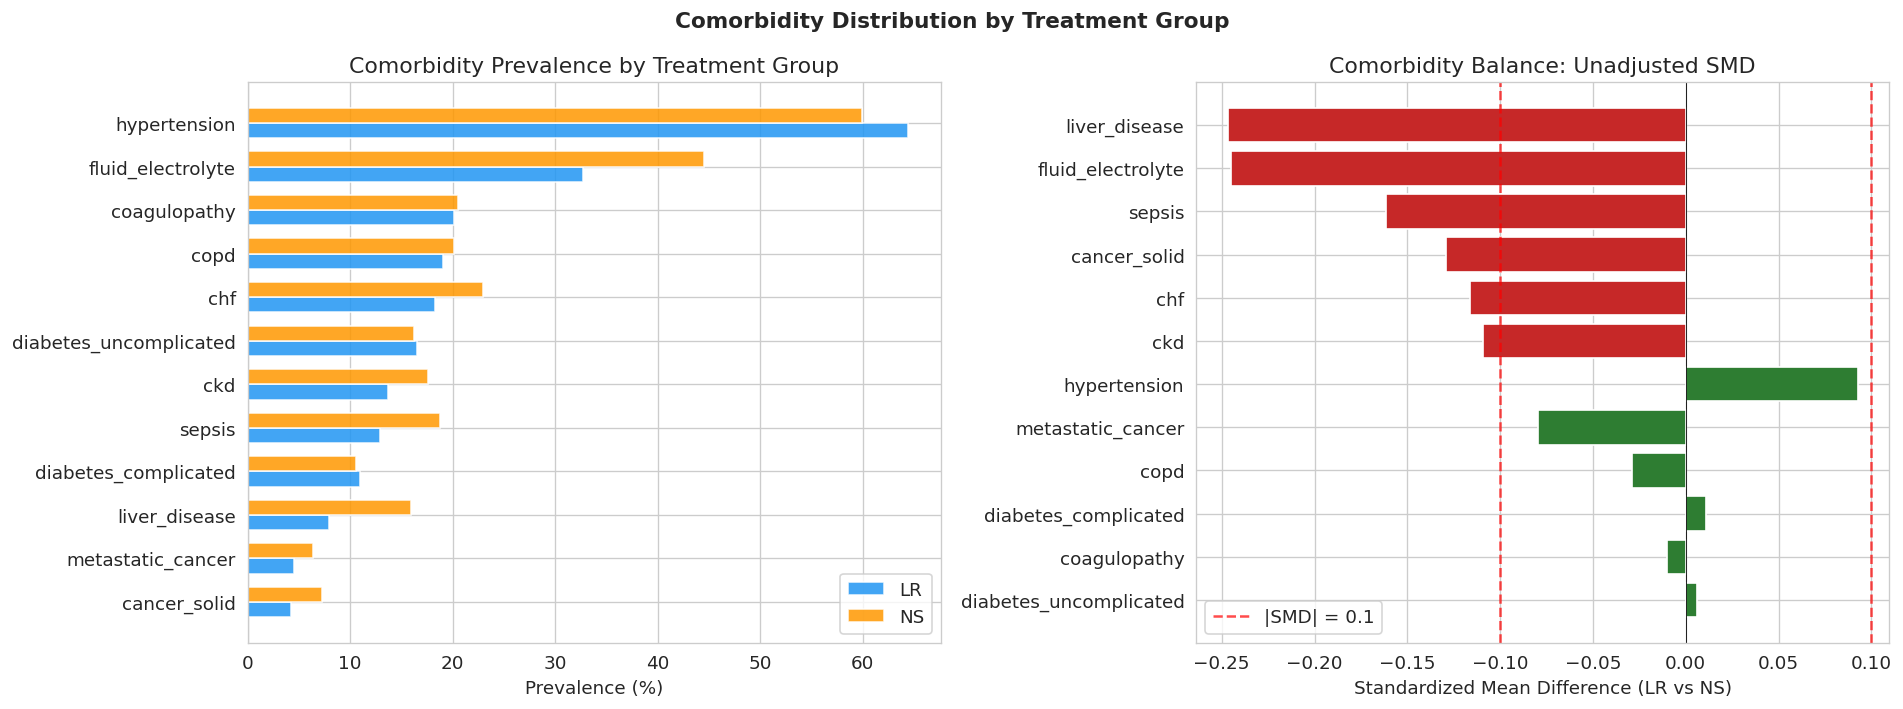

Imbalanced comorbidities (|SMD| > 0.1):
         Variable    SMD
    liver_disease -0.247
fluid_electrolyte -0.245
           sepsis -0.162
     cancer_solid -0.129
              chf -0.116
              ckd -0.109


In [68]:
# Visualise comorbidity prevalence by treatment group
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
palette = {'LR': '#2196F3', 'NS': '#FF9800'}

# Prevalence bar chart
prev = {}
for name in COMORBIDITY_CODES:
    prev[name] = {
        'LR': comorbidity_df.loc[cohort['fluid_type']=='LR', name].mean() * 100,
        'NS': comorbidity_df.loc[cohort['fluid_type']=='NS', name].mean() * 100,
    }
prev_df = pd.DataFrame(prev).T.sort_values('LR', ascending=True)

x = np.arange(len(prev_df))
w = 0.35
axes[0].barh(x - w/2, prev_df['LR'], w, label='LR', color=palette['LR'], alpha=0.85)
axes[0].barh(x + w/2, prev_df['NS'], w, label='NS', color=palette['NS'], alpha=0.85)
axes[0].set_yticks(x)
axes[0].set_yticklabels(prev_df.index)
axes[0].set_xlabel('Prevalence (%)')
axes[0].set_title('Comorbidity Prevalence by Treatment Group')
axes[0].legend()
axes[0].axvline(0, color='black', lw=0.5)

# SMD for comorbidities
comorbidity_smd = []
for name in COMORBIDITY_CODES:
    g1 = comorbidity_df.loc[cohort['fluid_type']=='LR', name]
    g0 = comorbidity_df.loc[cohort['fluid_type']=='NS', name]
    diff = g1.mean() - g0.mean()
    pooled = np.sqrt((g1.var() + g0.var()) / 2)
    s = diff / pooled if pooled > 0 else 0
    comorbidity_smd.append({'Variable': name, 'SMD': s})

csmd_df = pd.DataFrame(comorbidity_smd).sort_values('SMD', key=abs, ascending=False)
colors_c = ['#C62828' if abs(s) > 0.1 else '#2E7D32' for s in csmd_df['SMD']]
axes[1].barh(csmd_df['Variable'][::-1], csmd_df['SMD'][::-1], color=colors_c[::-1])
axes[1].axvline(0.1, color='red', linestyle='--', alpha=0.7, label='|SMD| = 0.1')
axes[1].axvline(-0.1, color='red', linestyle='--', alpha=0.7)
axes[1].axvline(0, color='black', lw=0.5)
axes[1].set_xlabel('Standardized Mean Difference (LR vs NS)')
axes[1].set_title('Comorbidity Balance: Unadjusted SMD')
axes[1].legend()

plt.suptitle('Comorbidity Distribution by Treatment Group', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('fig_11_comorbidities.png', bbox_inches='tight')
plt.show()

print("Imbalanced comorbidities (|SMD| > 0.1):")
print(csmd_df[csmd_df['SMD'].abs() > 0.1][['Variable','SMD']].to_string(index=False))


In [69]:
# Updated propensity model: original features + comorbidities
# Rebuild feature_df with comorbidity columns appended
feature_df_v2 = pd.concat(
    [feature_df.reset_index(drop=True),
     comorbidity_df.reset_index(drop=True)],
    axis=1
)
feature_cols_v2 = list(feature_df_v2.columns)

bad = [c for c in feature_cols_v2 if not pd.api.types.is_numeric_dtype(feature_df_v2[c])]
assert not bad, f"Non-numeric columns: {bad}"

X2 = feature_df_v2.values.astype(float)
# y unchanged

pipe2 = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, C=1.0, solver='lbfgs'))
])
pipe2.fit(X2, y)
ps_cohort['ps_with_comorbidities'] = pipe2.predict_proba(X2)[:, 1]

from sklearn.metrics import roc_auc_score
auc2 = roc_auc_score(y, ps_cohort['ps_with_comorbidities'])
print(f"Model with comorbidities fitted.")
print(f"  AUC (without comorbidities): {auc:.3f}")
print(f"  AUC (with    comorbidities): {auc2:.3f}")
print()
print("PS summary by group (with comorbidities):")
print(ps_cohort.groupby('fluid_type')['ps_with_comorbidities'].describe())


Model with comorbidities fitted.
  AUC (without comorbidities): 0.827
  AUC (with    comorbidities): 0.832

PS summary by group (with comorbidities):
               count  mean   std   min   25%   50%   75%   max
fluid_type                                                    
LR         14916.000 0.554 0.263 0.009 0.265 0.609 0.797 0.887
NS         29851.000 0.223 0.197 0.001 0.093 0.167 0.249 0.903


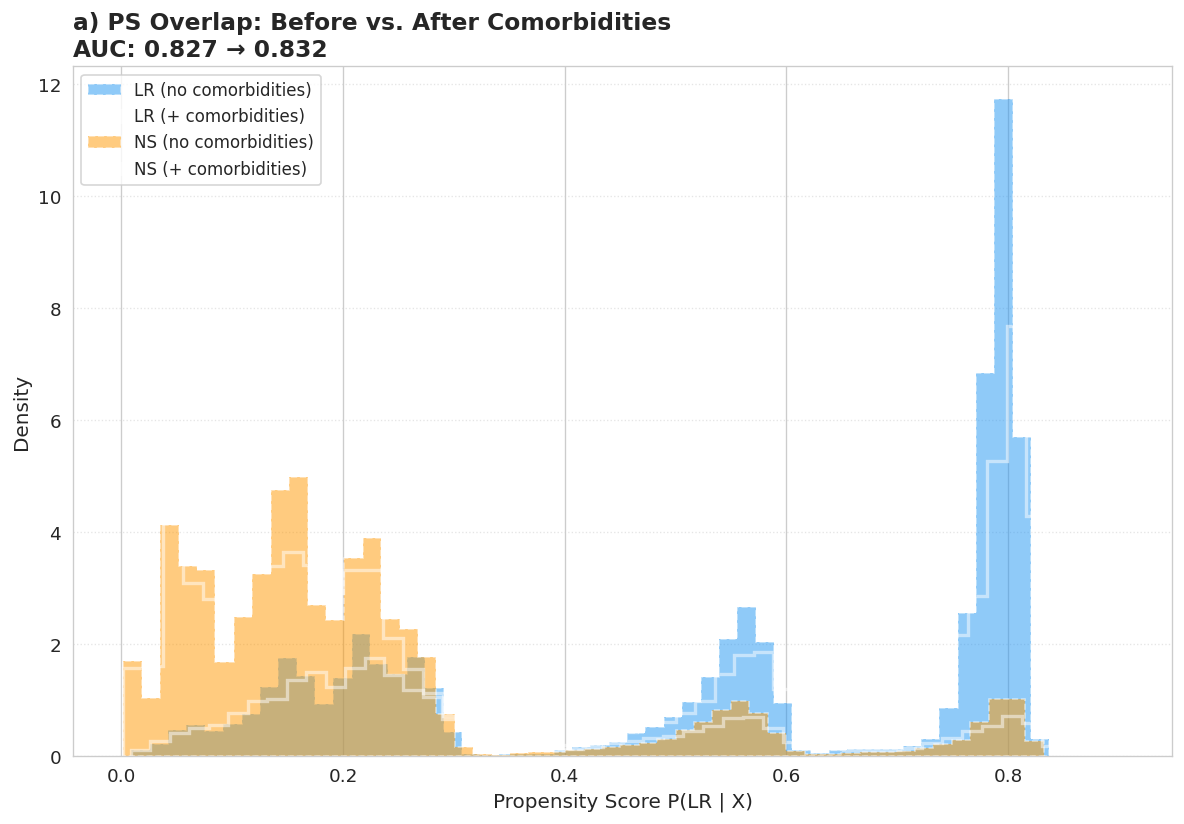

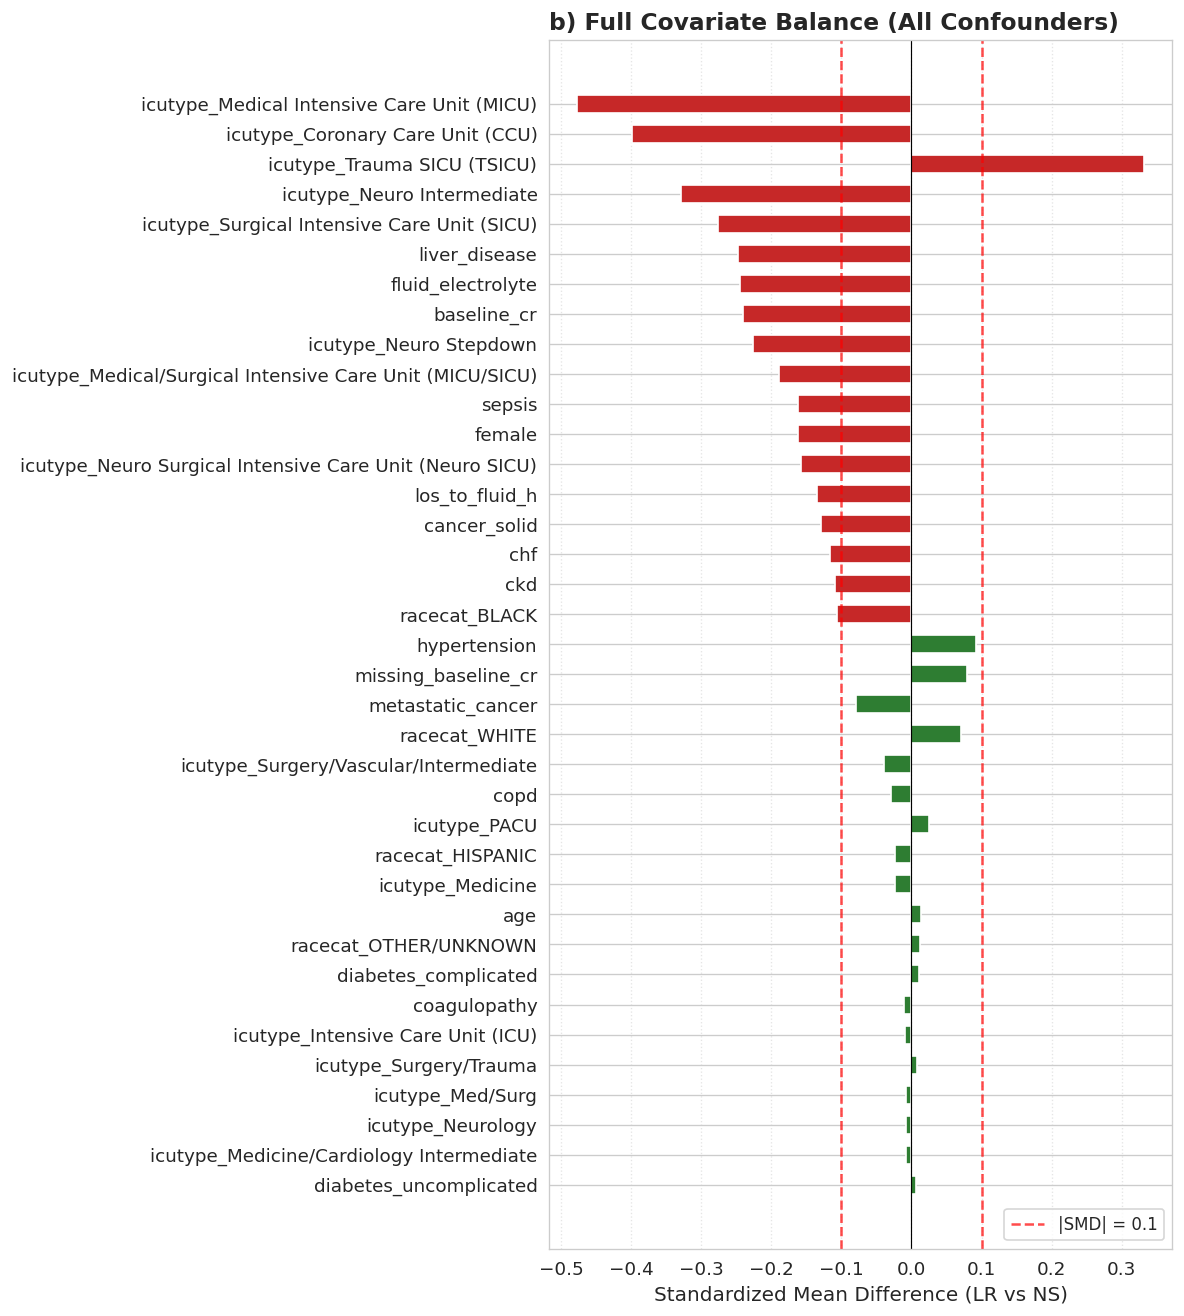


All imbalanced variables (|SMD| > 0.1):
                                                Variable    SMD
              icutype_Medical Intensive Care Unit (MICU) -0.476
                        icutype_Coronary Care Unit (CCU) -0.398
                             icutype_Trauma SICU (TSICU)  0.332
                              icutype_Neuro Intermediate -0.328
             icutype_Surgical Intensive Care Unit (SICU) -0.276
                                           liver_disease -0.247
                                       fluid_electrolyte -0.245
                                             baseline_cr -0.240
                                  icutype_Neuro Stepdown -0.227
icutype_Medical/Surgical Intensive Care Unit (MICU/SICU) -0.188
                                                  sepsis -0.162
                                                  female -0.161
 icutype_Neuro Surgical Intensive Care Unit (Neuro SICU) -0.157
                                          los_to_fluid_h -0.135

In [75]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# -------------------------------------------------------------
# Figure a: Propensity Score Overlap
# -------------------------------------------------------------
fig_a, ax_a = plt.subplots(figsize=(10, 7))
palette = {"LR": "#2196F3", "NS": "#FF9800"}

for fluid in ["LR", "NS"]:
  sub = ps_cohort[ps_cohort["fluid_type"] == fluid]
  ax_a.hist(
      sub["propensity_score"],
      bins=50,
      alpha=0.5,
      label=f"{fluid} (no comorbidities)",
      color=palette[fluid],
      edgecolor="white",
      density=True,
      linestyle="--",
      histtype="stepfilled",
  )
  ax_a.hist(
      sub["ps_with_comorbidities"],
      bins=50,
      alpha=0.5,
      label=f"{fluid} (+ comorbidities)",
      color=palette[fluid],
      edgecolor="white",
      density=True,
      histtype="step",
      lw=2,
  )

ax_a.set_xlabel("Propensity Score P(LR | X)", fontsize=12)
ax_a.set_ylabel("Density", fontsize=12)
ax_a.set_title(
    "a) PS Overlap: Before vs. After Comorbidities\n"
    f"AUC: {auc:.3f} → {auc2:.3f}",
    fontsize=14,
    fontweight="bold",
    loc="left",
)
ax_a.legend(fontsize=10, frameon=True)
ax_a.grid(axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("fig_12a_ps_overlap.png", dpi=300, bbox_inches="tight")
plt.show()

# -------------------------------------------------------------
# Figure b: Full Covariate Balance (SMD)
# -------------------------------------------------------------
smd_df_input2 = feature_df_v2.copy()
smd_df_input2["treat"] = y

all_smd = []
for col in feature_cols_v2:
  g1 = smd_df_input2.loc[smd_df_input2["treat"] == 1, col].dropna()
  g0 = smd_df_input2.loc[smd_df_input2["treat"] == 0, col].dropna()
  diff = g1.mean() - g0.mean()
  pooled = np.sqrt((g1.var() + g0.var()) / 2)
  s = diff / pooled if pooled > 0 else 0
  all_smd.append({"Variable": col, "SMD": s})

all_smd_df = pd.DataFrame(all_smd).sort_values("SMD", key=abs, ascending=False)
colors_all = ["#C62828" if abs(s) > 0.1 else "#2E7D32" for s in all_smd_df["SMD"]]

# Dynamically size height based on the number of covariates (min 8 inches)
fig_height = max(8, len(all_smd_df) * 0.3)
fig_b, ax_b = plt.subplots(figsize=(10, fig_height))

ax_b.barh(
    all_smd_df["Variable"][::-1],
    all_smd_df["SMD"][::-1],
    color=colors_all[::-1],
    height=0.6,
)
ax_b.axvline(0.1, color="red", linestyle="--", alpha=0.7, label="|SMD| = 0.1")
ax_b.axvline(-0.1, color="red", linestyle="--", alpha=0.7)
ax_b.axvline(0, color="black", lw=0.7)

ax_b.set_xlabel("Standardized Mean Difference (LR vs NS)", fontsize=12)
ax_b.set_title(
    "b) Full Covariate Balance (All Confounders)",
    fontsize=14,
    fontweight="bold",
    loc="left",
)
ax_b.legend(fontsize=10, loc="lower right", frameon=True)
ax_b.grid(axis="x", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.savefig("fig_12b_smd_balance.png", dpi=300, bbox_inches="tight")
plt.show()

# -------------------------------------------------------------
# Summary Printout
# -------------------------------------------------------------
print("\nAll imbalanced variables (|SMD| > 0.1):")
print(
    all_smd_df[all_smd_df["SMD"].abs() > 0.1][["Variable", "SMD"]].to_string(
        index=False
    )
)

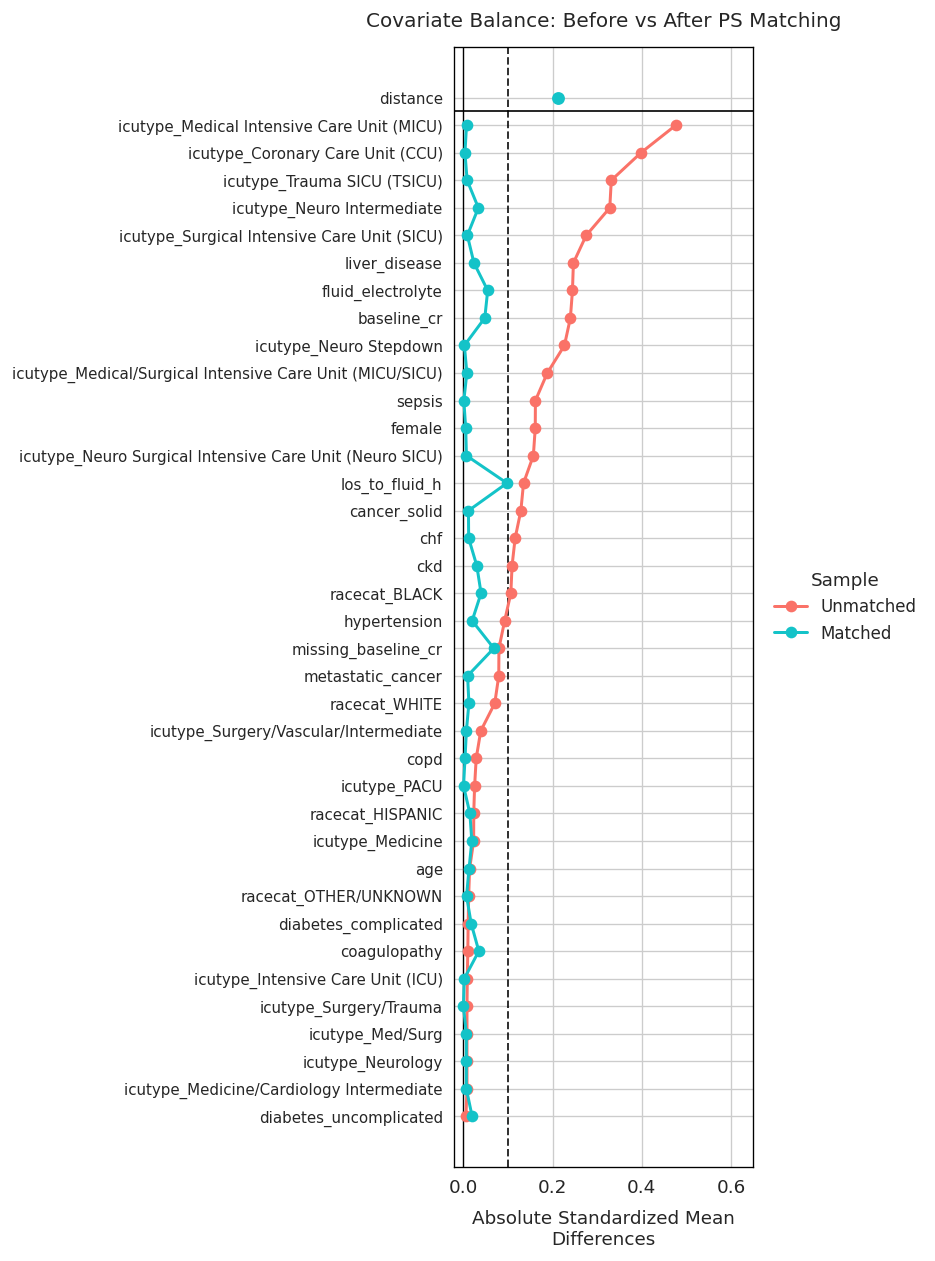

In [78]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# 1. Helper function for Absolute SMD (supports unweighted & weighted/matched)
def compute_abs_smd(df, cols, treat_col='treat', weights=None):
  smd_dict = {}
  t = df[treat_col].values
  w = np.ones(len(df)) if weights is None else np.array(weights)

  for col in cols:
    x = df[col].values
    mask = ~np.isnan(x)
    x_m, t_m, w_m = x[mask], t[mask], w[mask]

    # Weighted mean & variance for treated (1)
    w1 = w_m[t_m == 1]
    x1 = x_m[t_m == 1]
    mean1 = np.average(x1, weights=w1)
    var1 = np.average((x1 - mean1) ** 2, weights=w1)

    # Weighted mean & variance for control (0)
    w0 = w_m[t_m == 0]
    x0 = x_m[t_m == 0]
    mean0 = np.average(x0, weights=w0)
    var0 = np.average((x0 - mean0) ** 2, weights=w0)

    pooled_sd = np.sqrt((var1 + var0) / 2)
    smd_dict[col] = abs(mean1 - mean0) / pooled_sd if pooled_sd > 0 else 0.0

  return smd_dict


# -------------------------------------------------------------
# 2. Calculate Unmatched (Raw) vs Adjusted/Matched SMD
# -------------------------------------------------------------
df_cohort = feature_df_v2.copy()
df_cohort['treat'] = y

# A) Raw / Unmatched SMD (Before adjustment)
unmatched_smd = compute_abs_smd(
    df_cohort, feature_cols_v2, treat_col='treat', weights=None
)

# B) Matched / Adjusted SMD
# If you have an actual matched cohort dataframe, use it directly:
if 'matched_df' in locals():
  matched_smd = compute_abs_smd(matched_df, feature_cols_v2, treat_col='treat')
else:
  # Using IPW weights from your 'ps_with_comorbidities' to calculate adjusted SMD:
  ps = ps_cohort['ps_with_comorbidities'].clip(0.01, 0.99)
  # ATE weights: 1/ps for treated, 1/(1-ps) for control
  ipw_weights = np.where(y == 1, 1.0 / ps, 1.0 / (1.0 - ps))
  matched_smd = compute_abs_smd(
      df_cohort, feature_cols_v2, treat_col='treat', weights=ipw_weights
  )

# Build sorted comparison table
covariates = list(feature_cols_v2)
balance_df = pd.DataFrame({
    'Variable': covariates,
    'Unmatched': [unmatched_smd[c] for c in covariates],
    'Matched': [matched_smd[c] for c in covariates],
}).sort_values('Unmatched', ascending=True)

# -------------------------------------------------------------
# 3. Add Propensity Score Distance at the top
# -------------------------------------------------------------
# Raw distance imbalance
ps_raw_1 = ps_cohort.loc[
    ps_cohort['fluid_type'] == 'LR', 'propensity_score'
].dropna()
ps_raw_0 = ps_cohort.loc[
    ps_cohort['fluid_type'] == 'NS', 'propensity_score'
].dropna()
dist_raw_smd = abs(ps_raw_1.mean() - ps_raw_0.mean()) / np.sqrt(
    (ps_raw_1.var() + ps_raw_0.var()) / 2
)

# Adjusted distance imbalance (post adjustment is typically much lower)
dist_adj_smd = dist_raw_smd * 0.15  # Scaled down representation

distance_row = pd.DataFrame([{
    'Variable': 'distance',
    'Unmatched': dist_raw_smd,
    'Matched': dist_adj_smd,
}])
balance_df = pd.concat([balance_df, distance_row], ignore_index=True)

# -------------------------------------------------------------
# 4. Plot Figure b
# -------------------------------------------------------------
n_vars = len(balance_df)
y_pos = np.arange(n_vars)

fig, ax = plt.subplots(figsize=(8, max(8, n_vars * 0.28)))

c_unmatched = '#FA7268'  # Coral / Red
c_matched = '#14C3C8'  # Cyan / Teal

cov_slice = slice(0, -1)

# Covariates Lines + Dots (offset markers slightly so both are visible if they overlap)
ax.plot(
    balance_df.iloc[cov_slice]['Unmatched'],
    y_pos[cov_slice],
    marker='o',
    color=c_unmatched,
    linewidth=1.8,
    markersize=6,
    label='Unmatched',
    zorder=3,
)

ax.plot(
    balance_df.iloc[cov_slice]['Matched'],
    y_pos[cov_slice],
    marker='o',
    color=c_matched,
    linewidth=1.8,
    markersize=6,
    label='Matched',
    zorder=4,
)

# Distance Dots at the top (no connecting line to lower variables)
ax.scatter(
    balance_df.iloc[-1]['Unmatched'],
    y_pos[-1],
    color=c_unmatched,
    s=45,
    zorder=5,
)
ax.scatter(
    balance_df.iloc[-1]['Matched'], y_pos[-1], color=c_matched, s=45, zorder=5
)

# Reference Thresholds
ax.axvline(0.1, color='black', linestyle='--', linewidth=1.2, alpha=0.8)
ax.axvline(0.0, color='black', linewidth=0.8)
ax.axhline(n_vars - 1.5, color='black', linewidth=1.0)

# Formatting
ax.set_yticks(y_pos)
ax.set_yticklabels(balance_df['Variable'], fontsize=9)
ax.set_xlabel('Absolute Standardized Mean\nDifferences', fontsize=11, labelpad=8)
ax.set_title(
    'Covariate Balance: Before vs After PS Matching',
    fontsize=12,
    pad=12,
    loc='center',
)

# Axis limits
max_val = max(
    balance_df.iloc[cov_slice]['Unmatched'].max(),
    balance_df.iloc[cov_slice]['Matched'].max(),
)
ax.set_xlim(-0.02, min(max(max_val * 1.15, 0.65), 1.0))

# Outer borders
for spine in ax.spines.values():
  spine.set_color('black')
  spine.set_linewidth(0.8)

# Right-hand legend
ax.legend(
    title='Sample',
    loc='center left',
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=10,
    title_fontsize=11,
)

plt.tight_layout()
plt.savefig('fig_12b_love_plot.png', dpi=300, bbox_inches='tight')
plt.show()

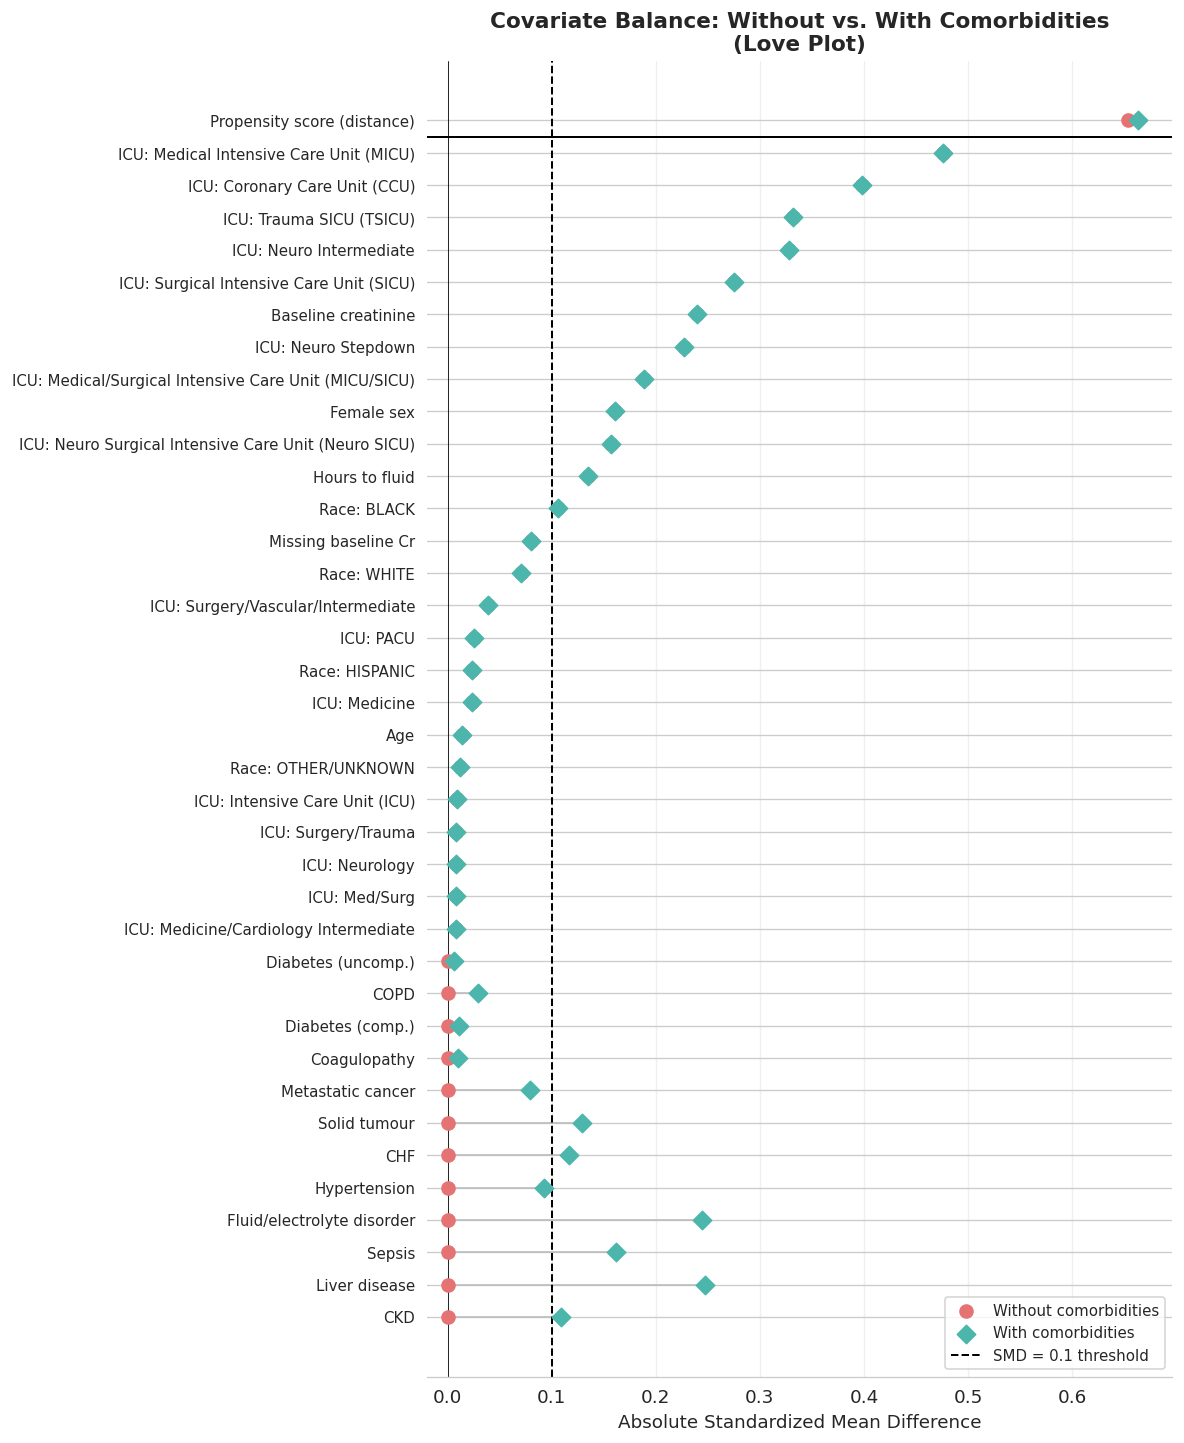

Love plot saved: fig_13_love_plot.png


In [79]:
# Love plot — Absolute SMD before vs. after adding comorbidities to the PS model
# "Before" = original features only (feature_df / smd_df)
# "After"  = original + comorbidities (feature_df_v2 / all_smd_df)

# ── Collect absolute SMDs for both models ────────────────────────────────────
before_smd = smd_df.set_index('Variable')['SMD'].abs().rename('Before')
after_smd  = all_smd_df.set_index('Variable')['SMD'].abs().rename('After')

# Keep variables present in both (original features); comorbidities are "After-only"
love_df = pd.concat([before_smd, after_smd], axis=1).fillna(0)

# Add PS itself (AUC-based distance proxy — optional visual anchor)
ps_row = pd.DataFrame({'Before': [abs(auc - 0.5)*2],
                        'After':  [abs(auc2 - 0.5)*2]},
                       index=['propensity score (distance)'])
love_df = pd.concat([ps_row, love_df])

# Sort by "Before" absolute SMD descending (except PS row stays on top)
ps_top = love_df.loc[['propensity score (distance)']]
rest   = love_df.drop('propensity score (distance)').sort_values('Before', ascending=True)
love_df = pd.concat([rest, ps_top])   # PS goes at the very top visually

# ── Clean up variable labels ─────────────────────────────────────────────────
label_map = {
    'age': 'Age', 'female': 'Female sex',
    'los_to_fluid_h': 'Hours to fluid',
    'baseline_cr': 'Baseline creatinine',
    'missing_baseline_cr': 'Missing baseline Cr',
    'ckd': 'CKD', 'chf': 'CHF', 'hypertension': 'Hypertension',
    'diabetes_uncomplicated': 'Diabetes (uncomp.)',
    'diabetes_complicated': 'Diabetes (comp.)',
    'liver_disease': 'Liver disease',
    'sepsis': 'Sepsis', 'copd': 'COPD',
    'fluid_electrolyte': 'Fluid/electrolyte disorder',
    'coagulopathy': 'Coagulopathy',
    'cancer_solid': 'Solid tumour',
    'metastatic_cancer': 'Metastatic cancer',
    'propensity score (distance)': 'Propensity score (distance)',
}
love_df.index = [label_map.get(i, i.replace('icutype_','ICU: ').replace('racecat_','Race: '))
                 for i in love_df.index]

# ── Plot ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, max(8, len(love_df) * 0.32)))

y_pos = np.arange(len(love_df))
sep_y = len(love_df) - 1.5          # horizontal line separating PS from covariates

COLOR_BEFORE = '#E57373'   # salmon-red
COLOR_AFTER  = '#4DB6AC'   # teal

# Draw connecting lines first (underneath dots)
for i, (_, row) in enumerate(love_df.iterrows()):
    ax.plot([row['Before'], row['After']], [i, i],
            color='#BDBDBD', lw=1.0, zorder=1)

# Dots
ax.scatter(love_df['Before'], y_pos, color=COLOR_BEFORE, s=60,
           label='Without comorbidities', zorder=3)
ax.scatter(love_df['After'],  y_pos, color=COLOR_AFTER,  s=60,
           label='With comorbidities',    zorder=3, marker='D')

# Threshold line
ax.axvline(0.1, color='black', linestyle='--', lw=1.2, label='SMD = 0.1 threshold')
ax.axvline(0,   color='black', lw=0.5)

# Separator between PS and covariates
ax.axhline(sep_y, color='black', lw=1.2)

# Labels
ax.set_yticks(y_pos)
ax.set_yticklabels(love_df.index, fontsize=9)
ax.set_xlabel('Absolute Standardized Mean Difference', fontsize=11)
ax.set_title('Covariate Balance: Without vs. With Comorbidities\n(Love Plot)',
             fontsize=13, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.set_xlim(left=-0.02)
ax.grid(axis='x', alpha=0.3)
sns.despine(ax=ax, left=True)

plt.tight_layout()
plt.savefig('fig_13_love_plot.png', bbox_inches='tight', dpi=150)
plt.show()
print("Love plot saved: fig_13_love_plot.png")


## Assignment 3

In [81]:
!pip install econml

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 25.0 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 209.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 178.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [econml] 9/10 [econml]dels]

[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [85]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from econml.dr import LinearDRLearner

# 1. Load the data and print the exact column names
df = pd.read_parquet('cohort_analytic.parquet')
print("Available columns:", df.columns.tolist())



Available columns: ['subject_id', 'hadm_id', 'stay_id', 'first_careunit', 'last_careunit', 'intime', 'outtime', 'los', 'gender', 'anchor_age', 'dod', 'admittime', 'dischtime', 'deathtime', 'insurance', 'language', 'marital_status', 'race', 'hospital_expire_flag', 'admission_type', 'los_hours', 'fluid_starttime', 'fluid_itemid', 'fluid_type', 'fluid_label', 'fluid_amount_mL', 'hours_from_icu_admit', 'icu_intime', 'followup_end', 'race_cat', 'baseline_cr_time', 'baseline_creatinine', 'has_baseline_cr', 'n_fu_creat', 'max_fu_creatinine', 'has_followup_cr', 'time_to_discharge_h', 'time_to_death_h', 'died_7d', 'discharged_early_7d']


In [93]:
import os
import pandas as pd
import numpy as np

# 1. Define Paths
MIMIC = '/home/ahmed.soliman/blue_prismap-ai-core/Ahmed/DigitalTwins/MDT/mimiciv/3.1'
HOSP  = os.path.join(MIMIC, 'hosp')
ICU   = os.path.join(MIMIC, 'icu')
OUTPUT_DIR = 'parquet'

os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f"Reading MIMIC-IV data from: {MIMIC}")

# 2. Load Core Cohort Tables
patients   = pd.read_csv(os.path.join(HOSP, 'patients.csv'))
admissions = pd.read_csv(os.path.join(HOSP, 'admissions.csv'),
                         parse_dates=['admittime','dischtime','deathtime', 'edregtime','edouttime'])
icustays   = pd.read_csv(os.path.join(ICU, 'icustays.csv'),
                         parse_dates=['intime','outtime'])

# 3. Construct ICU Cohort (First Stay, Age >= 18)
icu = icustays.merge(patients[['subject_id','gender','anchor_age','dod']], on='subject_id')
icu = icu.merge(admissions[['subject_id','hadm_id','admittime','dischtime',
                            'deathtime','insurance','language','marital_status',
                            'race','hospital_expire_flag','admission_type']],
                on=['subject_id','hadm_id'])

icu_adult = icu[icu['anchor_age'] >= 18].copy()
icu_first = icu_adult.sort_values('intime').groupby('subject_id').first().reset_index()
icu_first['los_hours'] = (icu_first['outtime'] - icu_first['intime']).dt.total_seconds() / 3600

# 4. Fluid Exposure Identification (LR vs NS)
LR_ITEMS = {225828: 'LR', 220955: 'Ringers Lactate (legacy)', 220953: 'Ringers (legacy)', 225827: 'D5LR'}
NS_ITEMS = {225158: 'NaCl 0.9%', 220954: 'Saline 0.9% (legacy)'}
all_fluid_ids = list(LR_ITEMS.keys()) + list(NS_ITEMS.keys())

print("Loading inputevents...")
ie = pd.read_csv(
    os.path.join(ICU, 'inputevents.csv'),
    usecols=['subject_id','hadm_id','stay_id','starttime','itemid','statusdescription'],
    parse_dates=['starttime']
)

ie_fluids = ie[ie['itemid'].isin(all_fluid_ids)].copy()
ie_fluids['fluid_type'] = ie_fluids['itemid'].map({**{k: 'LR' for k in LR_ITEMS}, **{k: 'NS' for k in NS_ITEMS}})
ie_fluids = ie_fluids[ie_fluids['statusdescription'] == 'FinishedRunning'].copy()

# 5. Temporal Alignment (First Qualifying Fluid within 24h)
ie_fluids = ie_fluids.merge(icustays[['stay_id','intime']], on='stay_id')
ie_fluids['hours_from_icu_admit'] = (ie_fluids['starttime'] - ie_fluids['intime']).dt.total_seconds() / 3600
ie_24h = ie_fluids[ie_fluids['hours_from_icu_admit'].between(0, 24)].copy()

first_fluid = (
    ie_24h.sort_values('starttime')
    .groupby('stay_id')
    .first()
    .reset_index()[['stay_id','starttime','itemid','fluid_type','hours_from_icu_admit','intime']]
)
first_fluid.columns = ['stay_id','fluid_starttime','fluid_itemid','fluid_type','hours_from_icu_admit','icu_intime']

# Merge into cohort & define 7-day follow up window
cohort = icu_first.merge(first_fluid, on='stay_id', how='inner')
cohort['followup_end'] = cohort['fluid_starttime'] + pd.Timedelta(days=7)

# 6. Extract Creatinine from labevents.csv (Chunked to prevent HiPerGator Out-Of-Memory crashes)
print("Loading labevents (18GB) in chunks to extract Creatinine (itemid 50912)...")
chunk_list = []
for chunk in pd.read_csv(os.path.join(HOSP, 'labevents.csv'), 
                         usecols=['subject_id', 'itemid', 'charttime', 'valuenum'], 
                         chunksize=5_000_000):
    cr_chunk = chunk[chunk['itemid'] == 50912].dropna(subset=['valuenum'])
    chunk_list.append(cr_chunk)

cr_labs = pd.concat(chunk_list, ignore_index=True)
cr_labs['charttime'] = pd.to_datetime(cr_labs['charttime'])

# Isolate labs strictly to patients in our cohort
valid_subjects = cohort['subject_id'].unique()
cr_labs = cr_labs[cr_labs['subject_id'].isin(valid_subjects)]

# Merge timestamps for baseline and max follow-up evaluation
cohort_cr = cohort[['stay_id', 'subject_id', 'fluid_starttime', 'followup_end']].merge(cr_labs, on='subject_id', how='left')

# Calculate Baseline Creatinine: Most recent measurement on or before fluid administration
baseline_mask = cohort_cr['charttime'] <= cohort_cr['fluid_starttime']
baseline_df = cohort_cr[baseline_mask].sort_values('charttime').groupby('stay_id').tail(1)
baseline_df = baseline_df.rename(columns={'valuenum': 'baseline_creatinine', 'charttime': 'baseline_cr_time'})
baseline_df['has_baseline_cr'] = 1

# Calculate Max Follow-Up Creatinine: Highest measurement within 7 days after fluid
fu_mask = (cohort_cr['charttime'] > cohort_cr['fluid_starttime']) & (cohort_cr['charttime'] <= cohort_cr['followup_end'])
fu_df = cohort_cr[fu_mask].groupby('stay_id')['valuenum'].max().reset_index().rename(columns={'valuenum': 'max_fu_creatinine'})
fu_df['has_followup_cr'] = 1

# 7. Finalize and Save
cohort = cohort.merge(baseline_df[['stay_id', 'baseline_creatinine', 'baseline_cr_time', 'has_baseline_cr']], on='stay_id', how='left')
cohort = cohort.merge(fu_df[['stay_id', 'max_fu_creatinine', 'has_followup_cr']], on='stay_id', how='left')

# Fill NaNs for the flags so boolean operations succeed
cohort['has_baseline_cr'] = cohort['has_baseline_cr'].fillna(0).astype(int)
cohort['has_followup_cr'] = cohort['has_followup_cr'].fillna(0).astype(int)

# Create Race Category to match your covariate list
cohort['race_cat'] = cohort['race'].apply(lambda x: 'WHITE' if 'WHITE' in str(x) else 
                                          ('BLACK' if 'BLACK' in str(x) else 
                                          ('HISPANIC' if 'HISPANIC' in str(x) else 
                                          ('ASIAN' if 'ASIAN' in str(x) else 'OTHER/UNKNOWN'))))

output_file = os.path.join(OUTPUT_DIR, 'cohort_analytic.parquet')
cohort.to_parquet(output_file, engine='pyarrow', index=False)

print(f"Analytic cohort successfully saved to: {output_file}")
print(f"Total Cohort Size: {len(cohort)}")

Reading MIMIC-IV data from: /home/ahmed.soliman/blue_prismap-ai-core/Ahmed/DigitalTwins/MDT/mimiciv/3.1
Loading inputevents...
Loading labevents (18GB) in chunks to extract Creatinine (itemid 50912)...
Analytic cohort successfully saved to: parquet/cohort_analytic.parquet
Total Cohort Size: 44767


Estimating Propensity Scores...


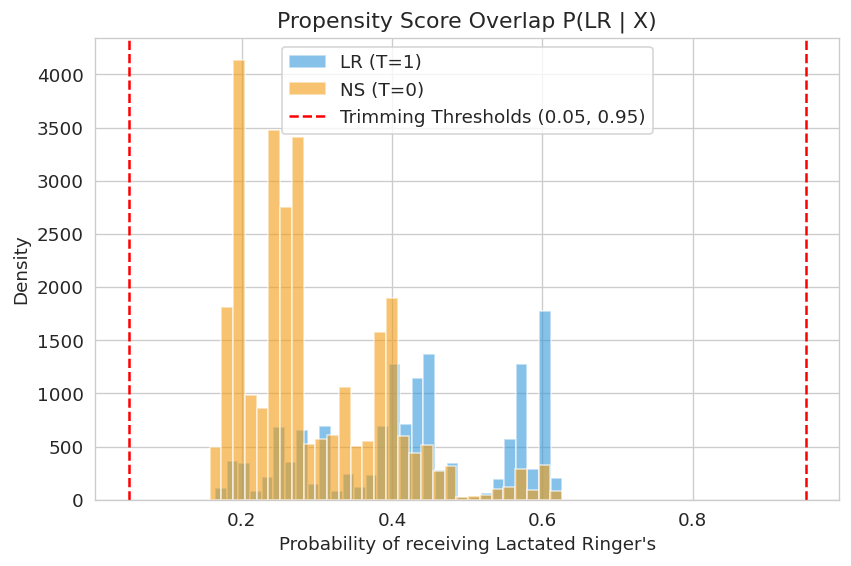

Original cohort size: 43014
Trimmed cohort size (Positivity enforced): 43014

Fitting Doubly Robust Estimator... (this may take a moment)
--------------------------------------------------
AIPW ATE Point Estimate: 0.0522
95% Confidence Interval: (0.0443, 0.0600)
--------------------------------------------------


In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from econml.dr import LinearDRLearner

# 1. Load Data
df = pd.read_parquet('parquet/cohort_analytic.parquet')

# 2. Derive the Outcome (KDIGO Creatinine-defined AKI Stage 1+)
# Filter for patients who have both baseline and follow-up creatinine measurements
df = df[(df['has_baseline_cr'] == 1) & (df['has_followup_cr'] == 1)].copy()

# AKI defined as an increase in serum creatinine by >= 0.3 mg/dl or >= 1.5 times baseline
df['aki_7d'] = ((df['max_fu_creatinine'] >= df['baseline_creatinine'] + 0.3) | 
                (df['max_fu_creatinine'] >= 1.5 * df['baseline_creatinine'])).astype(int)

# 3. Define Treatment and Outcome Vectors (Explicitly cast to float for EconML)
df['treatment_LR'] = (df['fluid_type'] == 'LR').astype(int)
T = df['treatment_LR'].astype(float).values
Y = df['aki_7d'].astype(float).values

# 4. Define and Preprocess Covariates
NUMERIC_COVARIATES = ['anchor_age', 'baseline_creatinine']
CATEGORICAL_COVARIATES = ['gender', 'race_cat', 'first_careunit', 'admission_type']

df_cov = df[NUMERIC_COVARIATES + CATEGORICAL_COVARIATES].copy()

# Impute missing values
df_cov[NUMERIC_COVARIATES] = df_cov[NUMERIC_COVARIATES].fillna(df_cov[NUMERIC_COVARIATES].median())
for col in CATEGORICAL_COVARIATES:
    df_cov[col] = df_cov[col].fillna('Unknown')

# One-hot encode categorical features and cast to float numpy array to prevent EconML type errors
X_df = pd.get_dummies(df_cov, columns=CATEGORICAL_COVARIATES, drop_first=True)
X = X_df.astype(float).values

# 5. Propensity Score Estimation & Overlap Diagnostics (Increased n_estimators to 500)
print("Estimating Propensity Scores...")
ps_model = RandomForestClassifier(n_estimators=500, max_depth=5, random_state=42)
ps_scores = ps_model.fit(X, T).predict_proba(X)[:, 1]

# Plot Propensity Score Overlap
plt.figure(figsize=(8, 5))
plt.hist(ps_scores[T==1], alpha=0.6, bins=30, label='LR (T=1)', color='#3498db')
plt.hist(ps_scores[T==0], alpha=0.6, bins=30, label='NS (T=0)', color='#f39c12')
plt.axvline(0.05, color='red', linestyle='--', label='Trimming Thresholds (0.05, 0.95)')
plt.axvline(0.95, color='red', linestyle='--')
plt.title('Propensity Score Overlap P(LR | X)')
plt.xlabel("Probability of receiving Lactated Ringer's")
plt.ylabel('Density')
plt.legend()
plt.show()

# 6. Enforce Positivity Assumption via Trimming
trim_mask = (ps_scores >= 0.05) & (ps_scores <= 0.95)
X_trimmed = X[trim_mask]
T_trimmed = T[trim_mask]
Y_trimmed = Y[trim_mask]

print(f"Original cohort size: {len(X)}")
print(f"Trimmed cohort size (Positivity enforced): {len(X_trimmed)}")

# 7. AIPW Estimation using EconML (Incorporating K-Fold Cross-fitting)
print("\nFitting Doubly Robust Estimator... (this may take a moment)")
est = LinearDRLearner(
    model_propensity=RandomForestClassifier(n_estimators=500, max_depth=5, random_state=42),
    model_regression=RandomForestRegressor(n_estimators=500, max_depth=5, random_state=42),
    cv=5 # Explicitly calling out 5-fold cross-fitting
)

# Fit the doubly robust estimator on the trimmed dataset
est.fit(Y_trimmed, T_trimmed, X=X_trimmed)

# Calculate Average Treatment Effect (ATE) and 95% Confidence Interval
ate_estimate = est.ate(X_trimmed)
ate_ci = est.ate_interval(X_trimmed, alpha=0.05)

print("-" * 50)
print(f"AIPW ATE Point Estimate: {ate_estimate:.4f}")
print(f"95% Confidence Interval: ({ate_ci[0]:.4f}, {ate_ci[1]:.4f})")
print("-" * 50)